# 데이터셋 설명

**RentTheRunway Clothing Fit Dataset**
미국 의류 대여 서비스 Rent the Runway 고객이 옷을 입어본 뒤 남긴 리뷰 데이터.
UCSD McAuley Lab에서 공개 ([다운로드](https://mcauleylab.ucsd.edu/public_datasets/data/datasets.html))

> Misra, R., Wan, M., & McAuley, J. (2018). Decomposing fit semantics for product size recommendation in metric spaces. *RecSys 2018*.

**규모**
리뷰 192,544건 · 사용자 105,508명 · 상품 5,850개

**주요 변수**

| 구분 | 변수 | 예시 |
| --- | --- | --- |
| 고객 정보 | 키, 몸무게, 가슴 사이즈, 나이 | 5' 8", 137lbs, 34d, 28 |
| 체형 | body type (고객이 직접 선택, 7종) | hourglass, pear, apple 등 |
| 옷 정보 | 옷 종류, 대여 사이즈 | dress, 14 |
| 결과 | fit (예측 대상) | small / fit / large |
| 기타 | 리뷰 글, 별점, 대여 목적 | "An adorable romper!..." |

**특징**
- 결과가 불균형함: 맞음 약 74%, 작음·큼 각각 약 13%
- 체형별 리뷰 수 차이가 큼: hourglass 55,349건 vs apple 4,877건
- 키·몸무게는 미국 단위(피트·인치, lbs)로 기록되어 변환 필요

In [ ]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

In [ ]:
BASE = "/content/drive/MyDrive/3-2/시각화 학술제"

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import re

import os
print(os.listdir("/content/drive/MyDrive"))

Mounted at /content/drive
['Colab Notebooks', 'GoodNotes', '3A4B-F0D36-66BC-947CF.pdf', 'pattern_metadata.txt', '조민서_논문세미나_Adaptive_Conformal_Predictions_Time_Series_완성본 (1).gslides', '3-2', '3-1', '3-여름학기', '1~2', 'eda_overview.png']


In [ ]:
print(os.listdir("/content/drive/MyDrive/3-2/시각화 학술제"))

['데이터 ', '코드']


In [ ]:
BASE = "/content/drive/MyDrive/3-2/시각화 학술제"
df = pd.read_json(f"{BASE}/데이터/원본/renttherunway_final_data.json.gz", lines=True)
print(len(df))

192544


In [ ]:
print(df.isna().sum())
print(df['fit'].value_counts())
print(df['body type'].value_counts())
df.head()

fit                   0
user_id               0
bust size         18411
item_id               0
weight            29982
rating               82
rented for           10
review_text           0
body type         14637
review_summary        0
category              0
height              677
size                  0
age                 960
review_date           0
dtype: int64
fit
fit      142058
small     25779
large     24707
Name: count, dtype: int64
body type
hourglass            55349
athletic             43667
pear                 22135
petite               22131
full bust            15006
straight & narrow    14742
apple                 4877
Name: count, dtype: int64


,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date
0,fit,420272,34d,2260466,137lbs,10.0,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28.0,"April 20, 2016"
1,fit,273551,34b,153475,132lbs,10.0,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36.0,"June 18, 2013"
2,fit,360448,NaN,1063761,NaN,10.0,party,This hugged in all the right places! It was a ...,NaN,It was a great time to celebrate the (almost) ...,sheath,"5' 4""",4,116.0,"December 14, 2015"
3,fit,909926,34c,126335,135lbs,8.0,formal affair,I rented this for my company's black tie award...,pear,Dress arrived on time and in perfect condition.,dress,"5' 5""",8,34.0,"February 12, 2014"
4,fit,151944,34b,616682,145lbs,10.0,wedding,I have always been petite in my upper body and...,athletic,Was in love with this dress !!!,gown,"5' 9""",12,27.0,"September 26, 2016"


In [ ]:
#단위 수정
df.columns = df.columns.str.replace(' ', '_')
df['review_id'] = range(len(df))

def to_cm(h):
    m = re.match(r"(\d+)' (\d+)\"", str(h))
    return (int(m[1]) * 12 + int(m[2])) * 2.54 if m else np.nan

df['height_cm'] = df['height'].apply(to_cm)
df['weight_kg'] = pd.to_numeric(df['weight'].str.replace('lbs', ''), errors='coerce') * 0.4536

bust = df['bust_size'].str.extract(r'(\d+)(.+)')
df['bust_band'] = pd.to_numeric(bust[0], errors='coerce')
df['cup'] = bust[1]

df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['label'] = df['fit'].map({'small': 0, 'fit': 1, 'large': 2})

df[['height', 'height_cm', 'weight', 'weight_kg', 'bust_size', 'bust_band', 'cup']].head()

,height,height_cm,weight,weight_kg,bust_size,bust_band,cup
0,"5' 8""",172.72,137lbs,62.1432,34d,34.0,d
1,"5' 6""",167.64,132lbs,59.8752,34b,34.0,b
2,"5' 4""",162.56,NaN,NaN,NaN,NaN,NaN
3,"5' 5""",165.10,135lbs,61.2360,34c,34.0,c
4,"5' 9""",175.26,145lbs,65.7720,34b,34.0,b


In [ ]:
#빈칸, 이상값 지우기

cols = ['height_cm', 'weight_kg', 'bust_band', 'cup', 'body_type',
        'category', 'size', 'age', 'label']
log = [('원본', len(df))]

clean = df.dropna(subset=cols)
log.append(('빈칸 제거', len(clean)))

clean = clean[clean['age'].between(15, 80)]
clean = clean[clean['height_cm'].between(140, 200)]
log.append(('이상값 제거', len(clean)))

dup_cols = [c for c in clean.columns if c != 'review_id']
clean = clean.drop_duplicates(subset=dup_cols)
log.append(('중복 제거', len(clean)))

print(pd.DataFrame(log, columns=['단계', '남은 줄 수']))

       단계  남은 줄 수
0      원본  192544
1   빈칸 제거  146438
2  이상값 제거  146299
3   중복 제거  146155


In [ ]:
print(clean['cup'].value_counts())
print(clean['category'].value_counts())

cup
b        42424
c        41621
d        36949
a        13460
dd        5388
d+        2900
ddd/e     1953
aa         628
g          362
f          313
h          112
i           26
j           19
Name: count, dtype: int64
category
dress           70330
gown            33279
sheath          14637
shift            4036
jumpsuit         4014
                ...  
sweatershirt        3
overcoat            1
crewneck            1
buttondown          1
sweatpants          1
Name: count, Length: 68, dtype: int64


In [ ]:
# ── 컵 사이즈를 숫자로 바꾸기 ──
# 컵은 aa < a < b < c < d < d+ < dd < ddd/e < f < g < h < i < j 순서로 커짐
# 글자 그대로 두면 AI가 크기 순서를 모르니까, 작은 컵부터 큰 컵까지 숫자를 매김
cup_order = {'aa': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'd+': 4.5, 'dd': 5,
             'ddd/e': 6, 'f': 7, 'g': 8, 'h': 9, 'i': 10, 'j': 11}

# cup 열의 글자를 위 표에 따라 숫자로 바꿔서 cup_num이라는 새 열에 저장
clean['cup_num'] = clean['cup'].map(cup_order)

# 표에 없는 컵이 있으면 숫자로 안 바뀌고 빈칸(NaN)이 됨
# 0이 나오면 모든 컵이 빠짐없이 숫자로 바뀐 것
print(clean['cup_num'].isna().sum())

0


In [ ]:
# ── 개수가 적은 옷 종류를 '기타'로 묶기 ──
# 옷 종류별로 리뷰가 몇 개씩 있는지 셈
cat_counts = clean['category'].value_counts()

# 리뷰가 500개 미만인 옷 종류 목록을 뽑음 (AI가 배우기엔 너무 적은 것들)
rare = cat_counts[cat_counts < 500].index

# 그 목록에 들어 있는 옷 종류는 전부 'other'로 바꾸고, 나머지는 그대로 둠
clean['category'] = clean['category'].where(~clean['category'].isin(rare), 'other')

# 정리 후 옷 종류가 몇 개 남았고 각각 몇 개인지 확인
print(clean['category'].value_counts())

category
dress         70330
gown          33279
sheath        14637
shift          4036
jumpsuit       4014
top            3779
other          3681
maxi           2597
romper         2447
jacket         1867
mini           1417
skirt          1204
sweater         917
coat            768
blazer          619
shirtdress      563
Name: count, dtype: int64


In [ ]:
# other로 묶인 옷 종류와 각각 원래 몇 개였는지 확인
print(cat_counts[rare])

# 몇 종류가 other로 들어갔는지
print(len(rare))

category
blouse          488
down            377
pants           322
vest            218
shirt           216
cardigan        195
frock           164
culottes        160
tank            141
tunic           134
suit            108
bomber          102
sweatshirt       97
leggings         94
print            89
legging          80
pant             79
cape             68
culotte          58
trouser          48
pullover         45
midi             39
knit             39
peacoat          33
poncho           33
kimono           24
turtleneck       23
trench           20
tee              17
parka            13
kaftan           13
tight            13
duster           12
ballgown         12
cami             12
trousers         11
t-shirt          11
hoodie           11
blouson          10
combo             7
henley            7
overalls          6
for               5
jogger            4
caftan            4
jeans             4
skirts            4
skort             4
sweatershirt      3
overcoat   

In [ ]:
# ── 전처리 전후로 체형별 리뷰 수 비교 ──
# 원본(df)과 정리본(clean)에서 체형별 리뷰 수를 각각 셈
before = df['body_type'].value_counts()
after = clean['body_type'].value_counts()

# 두 결과를 한 표로 합치고, 체형마다 몇 %가 남았는지 계산
check = pd.DataFrame({'전처리 전': before, '전처리 후': after})
check['남은 비율'] = (check['전처리 후'] / check['전처리 전']).round(3)
display(check)

,전처리 전,전처리 후,남은 비율
body_type,,,
apple,4877,3801,0.779
athletic,43667,37478,0.858
full bust,15006,10789,0.719
hourglass,55349,43918,0.793
pear,22135,18005,0.813
petite,22131,19318,0.873
straight & narrow,14742,12846,0.871


## 전처리 방식 수정

**문제**
입력 변수 중 하나라도 비면 행을 삭제했더니, 체형별 잔존 비율이 71.9%(full bust)~87.3%(petite)로 약 15%p 차이가 났다.

**수정**
- 체형, 결과(fit), 옷 종류, 사이즈가 빈 행만 삭제
- 키·몸무게·가슴 사이즈·나이의 결측치는 그대로 둠 (LightGBM이 자체 처리)
- 이상값 제거(나이 15~80세, 키 140~200cm)는 값이 있을 때만 적용

**결과**
192,544행 → 177,549행. 체형별 잔존 비율 99.7~99.9%로 차이가 사라짐

**추가 정리**
- 몸무게 36kg 미만 9건은 입력 오류로 보고 결측 처리 (행은 유지)
- 리뷰 글까지 같은 중복 25건 삭제 → 최종 **177,524행**
- 리뷰의 "N/A", "None"이 결측으로 읽히지 않도록 `keep_default_na=False, na_values=['']`로 불러옴

> 키·몸무게 구간별 비교에서는 해당 값이 빈 행을 제외한다.

In [ ]:
# ── 체형·결과·옷 정보가 빈 줄만 지우고, 몸 치수 빈칸은 남기기 ──
# 꼭 있어야 하는 열: 체형(그룹 구분), 결과(정답), 옷 종류와 사이즈
must = ['body_type', 'label', 'category', 'size']
clean2 = df.dropna(subset=must)

# 이상값 제거는 값이 있는 경우에만 적용 (빈칸은 그대로 통과)
clean2 = clean2[clean2['age'].isna() | clean2['age'].between(15, 80)]
clean2 = clean2[clean2['height_cm'].isna() | clean2['height_cm'].between(140, 200)]

# 중복 제거
dup_cols = [c for c in clean2.columns if c != 'review_id']
clean2 = clean2.drop_duplicates(subset=dup_cols)

# 체형별로 얼마나 남았는지 다시 비교
after2 = clean2['body_type'].value_counts()
check2 = pd.DataFrame({'전처리 전': before, '전처리 후': after2})
check2['남은 비율'] = (check2['전처리 후'] / check2['전처리 전']).round(3)
print(len(clean2))
print(check2)

177549
                   전처리 전  전처리 후  남은 비율
body_type                             
apple               4877   4867  0.998
athletic           43667  43603  0.999
full bust          15006  14981  0.998
hourglass          55349  55233  0.998
pear               22135  22075  0.997
petite             22131  22077  0.998
straight & narrow  14742  14713  0.998


In [ ]:
# ── 컵 사이즈를 숫자로 바꾸기 (clean2 기준) ──
cup_order = {'aa': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'd+': 4.5, 'dd': 5,
             'ddd/e': 6, 'f': 7, 'g': 8, 'h': 9, 'i': 10, 'j': 11}
clean2['cup_num'] = clean2['cup'].map(cup_order)

# 이제는 가슴 사이즈가 원래 빈 줄이 남아 있어서 NaN이 나오는 게 정상
# 아래 두 숫자가 같으면, 원래 빈칸이었던 것만 NaN이고 나머지는 전부 변환된 것
print(clean2['cup_num'].isna().sum(), clean2['cup'].isna().sum())

12292 12292


In [ ]:
# ── 개수가 적은 옷 종류를 '기타'로 묶기 (clean2 기준) ──
cat_counts = clean2['category'].value_counts()
rare = cat_counts[cat_counts < 500].index
clean2['category'] = clean2['category'].where(~clean2['category'].isin(rare), 'other')
print(clean2['category'].value_counts())

category
dress         85556
gown          40860
sheath        17796
shift          5008
jumpsuit       4717
top            4507
other          3708
maxi           3190
romper         2869
jacket         2251
mini           1692
skirt          1415
sweater        1059
coat            915
blazer          726
shirtdress      680
blouse          600
Name: count, dtype: int64


In [ ]:
# ── 체형별 기초 통계표 ──
# 체형별 리뷰 수와 사람 수
stats = clean2.groupby('body_type').agg(
    리뷰수=('review_id', 'count'),
    사람수=('user_id', 'nunique'))

# 체형별 작음·맞음·큼 비율
ratio = pd.crosstab(clean2['body_type'], clean2['fit'], normalize='index').round(3)

stats = stats.join(ratio).sort_values('리뷰수', ascending=False)
display(stats)

,리뷰수,사람수,fit,large,small
body_type,,,,,
hourglass,55233,29743,0.738,0.130,0.132
athletic,43603,23836,0.743,0.120,0.137
petite,22077,12219,0.743,0.131,0.126
pear,22075,11899,0.729,0.145,0.127
full bust,14981,8029,0.718,0.140,0.142
straight & narrow,14713,7488,0.746,0.121,0.134
apple,4867,2807,0.716,0.136,0.148


In [ ]:
# ── 사람 단위로 학습용·보정용·시험용 나누기 ──
# 랜덤 시드를 42로 고정해서 누가 돌려도 같은 결과가 나오게 함
rng = np.random.default_rng(42)

# 정리된 데이터에 있는 사람(user_id) 목록을 중복 없이 뽑고 무작위로 섞음
users = clean2['user_id'].unique()
rng.shuffle(users)

# 섞인 순서대로 앞 60%는 학습용, 다음 20%는 보정용, 나머지 20%는 시험용
n = len(users)
split = pd.DataFrame({'user_id': users})
split['set'] = 'test'
split.loc[:int(n * 0.6) - 1, 'set'] = 'train'
split.loc[int(n * 0.6):int(n * 0.8) - 1, 'set'] = 'cal'

# 분할명단 저장
split.to_csv(f"{BASE}/데이터/정리/분할명단.csv", index=False)

# 사람 수가 대략 6:2:2로 나뉘었는지 확인
print(split['set'].value_counts())

# 리뷰 수 기준으로도 비율 확인 (사람마다 리뷰 수가 달라서 정확히 6:2:2는 아닐 수 있음)
print(clean2.merge(split, on='user_id')['set'].value_counts(normalize=True).round(3))

set
train    57612
test     19205
cal      19204
Name: count, dtype: int64
set
train    0.596
test     0.203
cal      0.201
Name: proportion, dtype: float64


In [ ]:
# ── 정리된 데이터 저장 ──
keep = ['review_id', 'user_id', 'item_id', 'height_cm', 'weight_kg', 'bust_band', 'cup_num',
        'body_type', 'category', 'size', 'age', 'fit', 'label', 'review_text']
clean2[keep].to_csv(f"{BASE}/데이터/정리/정리데이터.csv", index=False)
print("저장 완료")

저장 완료


In [ ]:
# 정리데이터 다시 읽기
# keep_default_na=False: "N/A", "None" 같은 글을 빈칸으로 바꾸지 않음
# na_values=['']: 진짜로 비어 있는 칸만 빈칸으로 처리
path = f"{BASE}/데이터/정리/정리데이터.csv"
c = pd.read_csv(path, keep_default_na=False, na_values=[''])

# 1. 몸무게 36kg 미만은 입력 실수로 보고 빈칸으로 바꿈 (줄은 남김)
print("바꿀 몸무게 개수:", (c['weight_kg'] < 36).sum())   # 9
c.loc[c['weight_kg'] < 36, 'weight_kg'] = np.nan

# 2. review_id만 다르고 나머지가 똑같은 중복 리뷰는 하나만 남김
dup_cols = [col for col in c.columns if col != 'review_id']
print("지울 중복 개수:", c.duplicated(subset=dup_cols).sum())   # 25
c = c.drop_duplicates(subset=dup_cols)

# 3. 다시 저장 (177,524줄이 나오면 정상)
print(len(c))
c.to_csv(path, index=False)

바꿀 몸무게 개수: 9
지울 중복 개수: 25
177524


# 다음 단계: 모델 학습

**목표**
고객 정보와 옷 정보를 넣으면 작음·맞음·큼 확률을 내는 AI를 만든다.
이 확률은 이후 체형별 성능 비교, 확신도 보정, conformal prediction에 모두 쓰인다.

**사용 데이터**
- `정리데이터.csv` (177,524행)
- `분할명단.csv`로 사람 단위 분할: 학습용 60% · 보정용 20% · 시험용 20%

**모델 설정**

| 항목 | 내용 |
| --- | --- |
| 모델 | LightGBM 다중 분류 |
| 입력 | 키, 몸무게, 가슴 둘레, 컵, 체형, 옷 종류, 사이즈, 나이 |
| 출력 | 작음(0) · 맞음(1) · 큼(2) 확률 |
| 불균형 처리 | `class_weight='balanced'` (맞음이 74%라 작음·큼에 가중치) |
| 결측치 | 대체하지 않고 LightGBM이 자체 처리 |
| 시드 | 42 |

**진행 순서**
1. 정리데이터에 분할명단을 user_id로 결합
2. 학습용 데이터로 모델 학습
3. 시험용 데이터로 전체 성능 확인 (작음·큼 재현율 중심)
4. 보정용·시험용 예측 확률 저장

**산출물**
- `예측결과/보정용_예측확률.csv`
- `예측결과/시험용_예측확률.csv`

> 예측 파일에는 확률(p)과 함께 확률 변환 전 원점수(z)도 저장한다. 원점수는 temperature scaling에 쓰인다.

In [ ]:
# ── 1. 라이브러리와 경로 설정 ──
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix

# 최상위 폴더 경로
BASE = "/content/drive/MyDrive/3-2/시각화 학술제"

# 폴더 구조에 맞춘 경로
CLEAN_PATH = f"{BASE}/데이터/정리/정리데이터.csv"
SPLIT_PATH = f"{BASE}/데이터/정리/분할명단.csv"
PRED_DIR   = f"{BASE}/예측결과"

# 예측결과 폴더가 없으면 새로 만듦 (이미 있으면 그냥 넘어감)
os.makedirs(PRED_DIR, exist_ok=True)

# 경로가 맞는지 확인 (둘 다 True가 나와야 함)
print(os.path.exists(CLEAN_PATH), os.path.exists(SPLIT_PATH))

Mounted at /content/drive
True True


In [ ]:
# ── 2. 파일 불러오기 ──
# 정리데이터: "N/A" 리뷰가 빈칸으로 바뀌지 않게 옵션을 붙여서 읽음
data = pd.read_csv(CLEAN_PATH, keep_default_na=False, na_values=[''])
split = pd.read_csv(SPLIT_PATH)

print(len(data))    # 177524
print(len(split))   # 96021 : 분할명단.csv에 있는 사람 수

177524
96021


In [ ]:
# ── 3. 분할명단 붙이고 세 덩어리로 나누기 ──
# user_id를 기준으로 각 리뷰에 train / cal / test 표시를 붙임
data = data.merge(split, on='user_id', how='left')
print(data['set'].isna().sum())   # 0이면 모든 리뷰가 배정된 것

# AI에 넣을 입력 변수 (user_id, item_id는 사람·옷을 외우는 걸 막으려고 뺌)
features = ['height_cm', 'weight_kg', 'bust_band', 'cup_num',
            'body_type', 'category', 'size', 'age']

# 글자로 된 열은 범주형으로 바꿈
# 나누기 전에 바꿔야 세 덩어리의 범주 목록이 똑같이 맞춰짐
for col in ['body_type', 'category']:
    data[col] = data[col].astype('category')

train = data[data['set'] == 'train']
cal   = data[data['set'] == 'cal']
test  = data[data['set'] == 'test']
print(len(train), len(cal), len(test))

0
105807 35696 36021


In [ ]:
# ── 4. 모델 학습 (early stopping 추가) ──
# 학습용 안에서 사람 단위로 10%를 떼어 검증용으로 씀 (보정용·시험용은 건드리지 않음)
rng = np.random.default_rng(42)
tr_users = train['user_id'].unique()
val_users = rng.choice(tr_users, size=int(len(tr_users) * 0.1), replace=False)
tr  = train[~train['user_id'].isin(val_users)]
val = train[train['user_id'].isin(val_users)]

# 나무 수는 넉넉히 2000개로 두고, 검증 성능이 50번 연속 안 좋아지면 멈춤
model = lgb.LGBMClassifier(
    objective='multiclass',
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    class_weight='balanced',
    random_state=42,
    verbose=-1)

model.fit(tr[features], tr['label'],
          eval_set=[(val[features], val['label'])],
          callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])

# 실제로 몇 개의 나무에서 멈췄는지 (논문에 적을 값)
print("사용된 나무 수:", model.best_iteration_)

Training until validation scores don't improve for 50 rounds
[100]	valid_0's multi_logloss: 1.04919
[200]	valid_0's multi_logloss: 1.04384
[300]	valid_0's multi_logloss: 1.04004
[400]	valid_0's multi_logloss: 1.03664
[500]	valid_0's multi_logloss: 1.03338
[600]	valid_0's multi_logloss: 1.03023
[700]	valid_0's multi_logloss: 1.02817
[800]	valid_0's multi_logloss: 1.02631
[900]	valid_0's multi_logloss: 1.02428
[1000]	valid_0's multi_logloss: 1.02176
[1100]	valid_0's multi_logloss: 1.01988
[1200]	valid_0's multi_logloss: 1.01806
[1300]	valid_0's multi_logloss: 1.0162
[1400]	valid_0's multi_logloss: 1.0152
[1500]	valid_0's multi_logloss: 1.01372
[1600]	valid_0's multi_logloss: 1.01228
[1700]	valid_0's multi_logloss: 1.01043
[1800]	valid_0's multi_logloss: 1.00956
[1900]	valid_0's multi_logloss: 1.00823
[2000]	valid_0's multi_logloss: 1.00691
Did not meet early stopping. Best iteration is:
[1994]	valid_0's multi_logloss: 1.00688
사용된 나무 수: 1994


## 2-1. 학습 방법 수정

**처음 방식의 문제**
- 처음엔 나무를 2,000개까지 쌓되, 검증 성능이 더 나아지지 않으면 멈추게 했다.
- 그런데 2,000개를 다 쓰고도 멈추지 않았다.
- 원인: 학습은 작음·큼에 가중치를 줘서 했는데, 검증 점수는 가중치 없이 매겼다.
  공부한 기준과 채점 기준이 달라, 언제 멈춰야 할지 제대로 판단하지 못했다.

**수정**
- 검증 점수도 학습과 같은 가중치로 매긴다 (`eval_sample_weight`).
- 학습 속도를 0.05 → 0.1로 올려, 적당한 지점에서 멈추게 한다.
.

In [ ]:
# ── 4. 모델 학습 (검증도 같은 가중치로 평가) ──
from sklearn.utils.class_weight import compute_sample_weight

# 학습 때와 똑같이 작음·큼에 가중치를 준 상태로 검증 점수를 매기기 위한 값
val_w = compute_sample_weight('balanced', val['label'])

model = lgb.LGBMClassifier(
    objective='multiclass',
    n_estimators=3000,
    learning_rate=0.1,        # 0.05 → 0.1: 더 빨리 배워서 적당한 지점에서 멈추게
    num_leaves=31,
    class_weight='balanced',
    random_state=42,
    verbose=-1)

model.fit(tr[features], tr['label'],
          eval_set=[(val[features], val['label'])],
          eval_sample_weight=[val_w],
          callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])

print("사용된 나무 수:", model.best_iteration_)

Training until validation scores don't improve for 50 rounds
[100]	valid_0's multi_logloss: 1.0203
Early stopping, best iteration is:
[66]	valid_0's multi_logloss: 1.01928
사용된 나무 수: 66


In [ ]:
# ── 5. 전체 성능 확인 (시험용) ──
# 각 리뷰마다 확률이 가장 높은 결과를 AI의 답으로 봄
pred = model.predict(test[features])

# recall = 실제 그 결과였던 것 중 AI가 맞힌 비율
#   small의 recall = 실제로 작았던 옷을 '작음'이라고 맞힌 비율 (이 연구의 핵심 지표)
print(classification_report(test['label'], pred,
                            target_names=['small', 'fit', 'large'], digits=3))

# 혼동행렬: 행 = 실제, 열 = AI 예측 (small, fit, large 순)
print(confusion_matrix(test['label'], pred))

              precision    recall  f1-score   support

       small      0.216     0.612     0.319      4768
         fit      0.797     0.319     0.456     26405
       large      0.211     0.517     0.300      4848

    accuracy                          0.385     36021
   macro avg      0.408     0.483     0.358     36021
weighted avg      0.641     0.385     0.417     36021

[[2920 1031  817]
 [9410 8435 8560]
 [1216 1124 2508]]


## 2-2. 모델 학습 결과

**학습 설정**
- LightGBM 다중 분류, `class_weight='balanced'`, `learning_rate=0.1`
- 학습용 중 10%(사람 단위)를 검증용으로 떼어 early stopping 적용 → **나무 66개**에서 종료

**시험용 성능** (36,021건)

| 결과 | 재현율 (recall) | 정밀도 (precision) | 실제 건수 |
| --- | --- | --- | --- |
| 작음 | **0.612** | 0.216 | 4,768 |
| 맞음 | 0.319 | 0.797 | 26,405 |
| 큼 | **0.517** | 0.211 | 4,848 |

전체 정확도 0.385 · macro F1 0.358

**해석**
- 작은 옷의 61%, 큰 옷의 52%를 맞혀 체형별 비교에 충분한 수준이다.
- 클래스 가중치로 작음·큼 탐지를 우선해, 맞는 옷도 작음·큼으로 예측하는 경우가 많다(맞음 재현율 0.319).-> 작은 옷을 놓치면 큰 벌점을 매기므로
- 이 연구는 체형 간 성능 차이를 보는 것이 목적이므로 전체 정확도보다 작음·큼 재현율을 주 지표로 쓴다.

In [ ]:
# ── 6. 보정용·시험용 예측 결과 저장 ──
def save_preds(df, name):
    # 세 결과 각각의 확률 (한 줄의 합이 1)
    prob = model.predict_proba(df[features])
    # 확률로 바꾸기 전 원점수 (temperature scaling에서 사용)
    raw = model.predict(df[features], raw_score=True)

    # 이후 분석에 필요한 정보만 남김
    out = df[['review_id', 'user_id', 'body_type', 'height_cm', 'weight_kg', 'label']].copy()
    out['p_small'], out['p_fit'], out['p_large'] = prob[:, 0], prob[:, 1], prob[:, 2]
    out['z_small'], out['z_fit'], out['z_large'] = raw[:, 0], raw[:, 1], raw[:, 2]

    save_path = f"{PRED_DIR}/{name}_예측확률.csv"
    out.to_csv(save_path, index=False)
    print(save_path, "저장 완료:", len(out), "줄")

save_preds(cal, '보정용')    # → 예측결과/보정용_예측확률.csv
save_preds(test, '시험용')   # → 예측결과/시험용_예측확률.csv

/content/drive/MyDrive/3-2/시각화 학술제/예측결과/보정용_예측확률.csv 저장 완료: 35696 줄
/content/drive/MyDrive/3-2/시각화 학술제/예측결과/시험용_예측확률.csv 저장 완료: 36021 줄


In [ ]:
# ── 7. 체형별 성능 비교 ──
# 저장한 시험용 예측 파일 불러오기
pt = pd.read_csv(f"{PRED_DIR}/시험용_예측확률.csv")

# 세 확률 중 가장 큰 쪽을 AI의 답으로 (0=작음, 1=맞음, 2=큼)
pt['pred'] = pt[['p_small', 'p_fit', 'p_large']].values.argmax(axis=1)

# 리뷰마다 "실제 작음/큼인지", "AI가 맞혔는지" 표시
pt['is_small'] = (pt['label'] == 0).astype(int)
pt['hit_small'] = ((pt['label'] == 0) & (pt['pred'] == 0)).astype(int)
pt['is_large'] = (pt['label'] == 2).astype(int)
pt['hit_large'] = ((pt['label'] == 2) & (pt['pred'] == 2)).astype(int)

# 체형별로 합쳐서 재현율 계산
g = pt.groupby('body_type').agg(
    리뷰수=('review_id', 'count'),
    사람수=('user_id', 'nunique'),
    실제작음=('is_small', 'sum'),
    맞힌작음=('hit_small', 'sum'),
    실제큼=('is_large', 'sum'),
    맞힌큼=('hit_large', 'sum'))
g['작음_재현율'] = (g['맞힌작음'] / g['실제작음']).round(3)
g['큼_재현율'] = (g['맞힌큼'] / g['실제큼']).round(3)
display(g.sort_values('리뷰수', ascending=False))

,리뷰수,사람수,실제작음,맞힌작음,실제큼,맞힌큼,작음_재현율,큼_재현율
body_type,,,,,,,,
hourglass,11147,5975,1490,875,1456,727,0.587,0.499
athletic,8532,4689,1145,734,1026,507,0.641,0.494
pear,4663,2442,584,323,710,407,0.553,0.573
petite,4447,2416,570,350,628,317,0.614,0.505
full bust,3394,1642,459,308,579,344,0.671,0.594
straight & narrow,2851,1505,368,219,329,151,0.595,0.459
apple,987,536,152,111,120,55,0.730,0.458


**해석**
- 작음 재현율은 pear가 가장 낮고(0.553), apple이 가장 높다(0.730).
- apple은 표본이 적어(작음 152건) 우연일 가능성이 있다. 제외하면 pear와 full bust 간 약 12%p 차이.
- pear는 작음은 가장 못 맞히지만 큼은 잘 맞혀, AI가 pear 고객에게 '큼'으로 기우는 경향이 있을 수 있다.

> 차이가 통계적으로 의미 있는지는 다음 단계의 부트스트랩 오차 범위로 확인한다.

In [ ]:
# ── 8. 오차 범위 구하기 (사람 단위 부트스트랩) ──
# 사람을 무작위로 다시 뽑아 재현율을 1000번 다시 계산하고,
# 그중 가운데 95%가 들어가는 범위를 오차 범위로 씀
rng = np.random.default_rng(42)

# 사람별로 먼저 합쳐둠 (같은 사람 리뷰는 한 묶음으로 뽑히게)
per_user = pt.groupby(['body_type', 'user_id'])[
    ['is_small', 'hit_small', 'is_large', 'hit_large']].sum().reset_index()

rows = []
for bt, d in per_user.groupby('body_type'):
    arr = d[['is_small', 'hit_small', 'is_large', 'hit_large']].values
    n = len(arr)
    rec_s, rec_l = [], []
    for _ in range(1000):
        s = arr[rng.integers(0, n, n)].sum(axis=0)   # 사람 n명을 중복 허용해 뽑기
        rec_s.append(s[1] / s[0])
        rec_l.append(s[3] / s[2])
    rows.append({'body_type': bt,
                 '작음_하한': np.percentile(rec_s, 2.5), '작음_상한': np.percentile(rec_s, 97.5),
                 '큼_하한': np.percentile(rec_l, 2.5), '큼_상한': np.percentile(rec_l, 97.5)})

ci = pd.DataFrame(rows).set_index('body_type').round(3)
result = g[['사람수', '실제작음', '작음_재현율', '실제큼', '큼_재현율']].join(ci)
display(result.sort_values('작음_재현율'))

,사람수,실제작음,작음_재현율,실제큼,큼_재현율,작음_하한,작음_상한,큼_하한,큼_상한
body_type,,,,,,,,,
pear,2442,584,0.553,710,0.573,0.509,0.595,0.529,0.614
hourglass,5975,1490,0.587,1456,0.499,0.560,0.616,0.473,0.526
straight & narrow,1505,368,0.595,329,0.459,0.534,0.655,0.399,0.516
petite,2416,570,0.614,628,0.505,0.568,0.655,0.461,0.546
athletic,4689,1145,0.641,1026,0.494,0.612,0.671,0.461,0.529
full bust,1642,459,0.671,579,0.594,0.626,0.718,0.466,0.676
apple,536,152,0.730,120,0.458,0.651,0.807,0.360,0.560


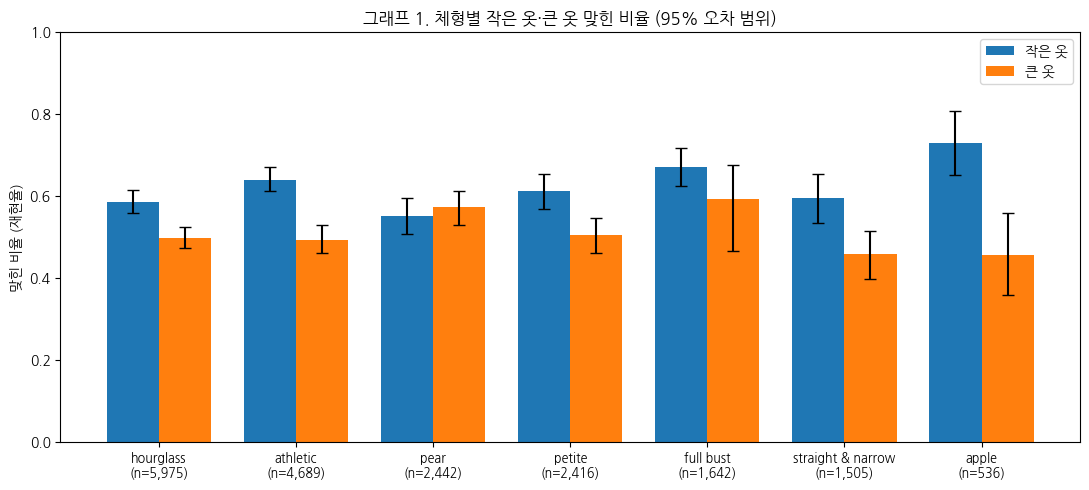

In [ ]:
# ── 그래프 1: 체형별 작음·큼 재현율 + 95% 오차 범위 ──
FIG_DIR = f"{BASE}/그래프"
os.makedirs(FIG_DIR, exist_ok=True)

# 모든 그래프에서 체형 순서를 똑같이 고정
order = ['hourglass', 'athletic', 'pear', 'petite', 'full bust', 'straight & narrow', 'apple']
labels = [f"{bt}\n(n={int(result.loc[bt, '사람수']):,})" for bt in order]

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(order)); w = 0.38
r = result.loc[order]

# 막대 = 재현율, 막대 위 세로선 = 95% 오차 범위
ax.bar(x - w/2, r['작음_재현율'], w, label='작은 옷',
       yerr=[r['작음_재현율'] - r['작음_하한'], r['작음_상한'] - r['작음_재현율']], capsize=4)
ax.bar(x + w/2, r['큼_재현율'], w, label='큰 옷',
       yerr=[r['큼_재현율'] - r['큼_하한'], r['큼_상한'] - r['큼_재현율']], capsize=4)

ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('맞힌 비율 (재현율)'); ax.set_ylim(0, 1); ax.legend()
ax.set_title('그래프 1. 체형별 작은 옷·큰 옷 맞힌 비율 (95% 오차 범위)')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프1.png", dpi=300); plt.show()

**그래프 1에서 보이는 점**
- pear는 **유일하게 큰 옷 막대가 작은 옷 막대보다 높은** 체형이다.
- 즉 AI가 pear 고객에게는 "클 거예요" 쪽으로 기우는 경향이 있다.
- 그 결과 실제로 작은 옷을 놓치는 경우가 늘어난다.

## 3-2. 체형별 차이가 우연인지 확인

시험용 사람을 바꿔가며 점수를 1,000번 다시 계산해, 점수가 오르내리는 범위를 구했다.
두 체형의 범위가 **겹치지 않으면 우연이 아닌 진짜 차이**다.

**결과**
- **작은 옷**: pear(51 ~ 60%)는 full bust(63 ~ 72%) 등과 범위가 겹치지 않는다.
  → AI는 pear 고객의 작은 옷을 **확실히 덜 맞힌다.**
- **큰 옷**: 체형끼리 범위가 대부분 겹쳐, 차이가 있다고 보기 어렵다.
- apple은 사람 수가 적어 범위가 가장 넓다.

> 다음 단계: 키·몸무게가 비슷한 사람끼리 비교해도 pear만 낮은지 확인한다.

In [ ]:
# ── 9. 키·몸무게 칸 나누기 ──
# 키나 몸무게가 빈 리뷰는 칸에 넣을 수 없어서 뺌
hw = pt.dropna(subset=['height_cm', 'weight_kg']).copy()

# 키는 10cm, 몸무게는 10kg 단위로 칸을 나눔
hw['키칸'] = pd.cut(hw['height_cm'], bins=[0, 150, 160, 170, 180, 300],
                   labels=['~150', '150~160', '160~170', '170~180', '180~'])
hw['몸무게칸'] = pd.cut(hw['weight_kg'], bins=[0, 50, 60, 70, 80, 300],
                     labels=['~50', '50~60', '60~70', '70~80', '80~'])
hw['칸'] = hw['키칸'].astype(str) + ' / ' + hw['몸무게칸'].astype(str)

# 실제로 작았던 리뷰만 남김 (작음 재현율을 계산하려고)
sm = hw[hw['is_small'] == 1]

# 체형마다 어느 칸에 사람이 몰려 있는지 확인 (가로 합이 1)
display(pd.crosstab(sm['body_type'], sm['몸무게칸'], normalize='index').round(2))

몸무게칸,~50,50~60,60~70,70~80,80~
body_type,,,,,
apple,0.00,0.15,0.36,0.38,0.11
athletic,0.02,0.41,0.45,0.10,0.02
full bust,0.01,0.33,0.31,0.25,0.10
hourglass,0.02,0.31,0.41,0.18,0.08
pear,0.01,0.30,0.45,0.17,0.07
petite,0.29,0.60,0.10,0.01,0.01
straight & narrow,0.07,0.67,0.23,0.03,0.01


In [ ]:
# ── 10. 같은 칸 안에서 체형별 작음 재현율 비교 ──
# 목적: 키·몸무게가 비슷한 사람끼리만 비교해서,
#       배형 점수가 낮은 게 체형 때문인지 키·몸무게 때문인지 가려냄

# [1단계] 칸마다, 체형마다 점수 계산
# 예: "160~170cm / 60~70kg" 칸의 배형 고객 중 실제 작았던 옷 80벌, AI가 맞힌 옷 44벌
cell = sm.groupby(['칸', 'body_type'], observed=True).agg(
    실제작음=('is_small', 'sum'), 맞힌작음=('hit_small', 'sum')).reset_index()

# 실제 작았던 옷이 30벌 미만인 칸은 숫자가 너무 적어 점수가 들쭉날쭉하므로 뺌
cell = cell[cell['실제작음'] >= 30]

# 칸마다 체형별 점수 = 맞힌 작음 ÷ 실제 작음
cell['재현율'] = cell['맞힌작음'] / cell['실제작음']

# [2단계] 모든 체형에 똑같이 적용할 "기준 키·몸무게 구성" 정하기
# 전체 데이터에서 각 칸에 사람이 얼마나 있는지 비율을 구함
# 예: "160~170 / 60~70" 칸이 전체의 25%면 기준비율 0.25
ref = sm['칸'].value_counts(normalize=True)
cell['기준비율'] = cell['칸'].map(ref)

# [3단계] 체형별 통제 후 점수 계산
# 각 칸 점수에 기준비율을 곱해서 더함 → 모든 체형이 똑같은 키·몸무게 구성을 가졌다면 몇 점일지
# 체형마다 빠진 칸이 있을 수 있어서, 가진 칸의 기준비율 합으로 나눠 다시 맞춤
adj = cell.groupby('body_type').apply(
    lambda d: (d['재현율'] * d['기준비율']).sum() / d['기준비율'].sum())

# [4단계] 통제 전 점수와 나란히 비교
# 통제 전: 그냥 계산한 원래 점수 (7번 셀 결과)
# 통제 후: 키·몸무게 구성을 똑같이 맞춘 점수
# 차이: 거의 0이면 키·몸무게는 원인이 아니라는 뜻
compare = pd.DataFrame({
    '통제 전': g['작음_재현율'],
    '키·몸무게 통제 후': adj.round(3)})
compare['차이'] = (compare['키·몸무게 통제 후'] - compare['통제 전']).round(3)
display(compare.sort_values('키·몸무게 통제 후'))

/tmp/ipykernel_1417/3161403247.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  adj = cell.groupby('body_type').apply(


,통제 전,키·몸무게 통제 후,차이
body_type,,,
pear,0.553,0.559,0.006
hourglass,0.587,0.586,-0.001
straight & narrow,0.595,0.613,0.018
petite,0.614,0.628,0.014
athletic,0.641,0.637,-0.004
full bust,0.671,0.684,0.013
apple,0.730,NaN,NaN


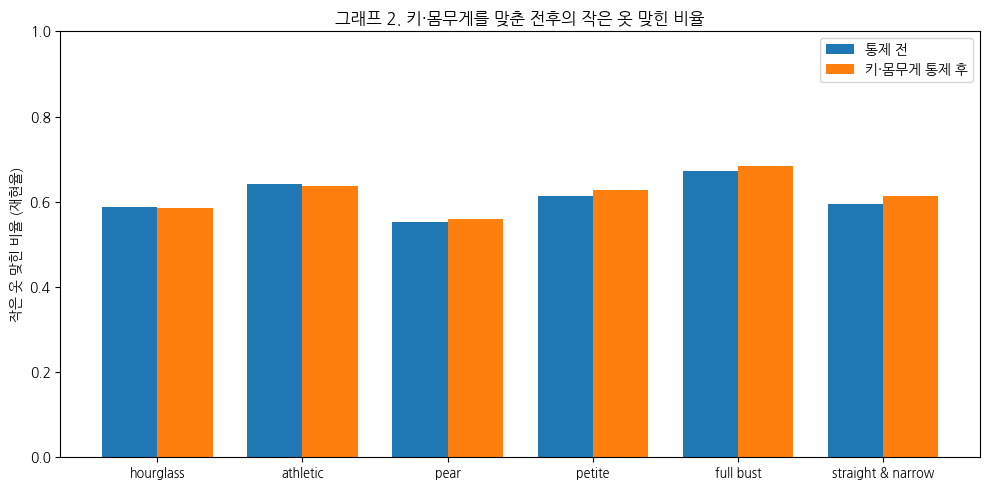

In [ ]:
# ── 그래프 2: 키·몸무게 통제 전후 작은 옷 맞힌 비율 ──
# 통제 후 점수가 계산된 체형만 사용 (apple은 사람 수가 적어 제외)
order2 = [bt for bt in order if not np.isnan(compare.loc[bt, '키·몸무게 통제 후'])]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(order2)); w = 0.38

# 왼쪽 막대 = 원래 점수, 오른쪽 막대 = 키·몸무게를 맞춘 뒤 점수
ax.bar(x - w/2, compare.loc[order2, '통제 전'], w, label='통제 전')
ax.bar(x + w/2, compare.loc[order2, '키·몸무게 통제 후'], w, label='키·몸무게 통제 후')

ax.set_xticks(x); ax.set_xticklabels(order2, fontsize=9)
ax.set_ylabel('작은 옷 맞힌 비율 (재현율)'); ax.set_ylim(0, 1); ax.legend()
ax.set_title('그래프 2. 키·몸무게를 맞춘 전후의 작은 옷 맞힌 비율')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프2.png", dpi=300); plt.show()

## 3-3. 키·몸무게를 맞춰도 배형이 낮을까?

**왜?**
배형 점수가 낮은 게 체형 때문이 아니라 몸무게나 키 때문일 수도 있어서.

**방법**
키·몸무게가 비슷한 사람끼리 묶은 뒤, 그 안에서 체형별로 작은 옷을 맞힌 비율을 비교했다.
몸 크기가 같은데도 AI가 작은 옷을 맞히는 비율이 체형마다 다르면, 그건 체형 때문이다.

**결과**
배형은 55.3% → 55.9%. 몸 크기를 맞춰도 **여전히 가장 낮다.**
(사과형은 사람 수가 적어 계산 불가)

**결론**
배형이 불리한 건 몸 크기가 아니라 **체형 때문**이다.

## 연구 질문 1 결과: 체형에 따라 AI 성능이 다른가?

**답: 다르다. AI는 배형 고객에게 불리하다.**

| 확인한 것 | 결과 |
| --- | --- |
| 체형별 작은 옷 맞힌 비율 | 배형 **55%** · 운동선수형 64% · 가슴 큰 형 67% |
| 우연인지 | 사람을 바꿔 1,000번 다시 계산해도 배형이 계속 낮음 → **우연 아님** |
| 몸 크기 때문인지 | 키·몸무게가 비슷한 사람끼리 비교해도 배형이 가장 낮음 → **체형 때문** |

> 배형 고객은 AI 추천을 믿고 샀다가 옷이 작아 반품할 가능성이 더 높다.

In [ ]:
# ── 11. 확신도 측정 도구 만들기 ──
import matplotlib.pyplot as plt

def ece(p, y, n_bins=15):
    # ECE: AI가 말한 확신과 실제 정답률이 평균적으로 얼마나 어긋나는지 (0에 가까울수록 정직)
    conf = p.max(axis=1)               # AI가 고른 답의 확률 = AI의 확신
    correct = (p.argmax(axis=1) == y)  # 실제로 맞혔는지
    bins = np.linspace(0, 1, n_bins + 1)
    total = 0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 0:
            # 이 구간에서 "말한 확신"과 "실제 정답률"의 차이 × 이 구간 비중
            total += abs(conf[m].mean() - correct[m].mean()) * m.mean()
    return total

def reliability(p, y, n_bins=15):
    # 신뢰도 그래프용: 확신 구간별 평균 확신과 실제 정답률
    conf = p.max(axis=1); correct = (p.argmax(axis=1) == y)
    bins = np.linspace(0, 1, n_bins + 1); xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 30:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return xs, ys

# 시험용·보정용 예측 불러오기
pc = pd.read_csv(f"{PRED_DIR}/보정용_예측확률.csv")
pcols, zcols = ['p_small', 'p_fit', 'p_large'], ['z_small', 'z_fit', 'z_large']

# 보정 전 ECE: 전체와 체형별
print("전체 ECE (보정 전):", round(ece(pt[pcols].values, pt['label'].values), 3))
print(pt.groupby('body_type').apply(
    lambda d: round(ece(d[pcols].values, d['label'].values), 3)))

전체 ECE (보정 전): 0.108
body_type
apple                0.167
athletic             0.111
full bust            0.133
hourglass            0.112
pear                 0.135
petite               0.080
straight & narrow    0.110
dtype: float64


/tmp/ipykernel_1417/821991973.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(pt.groupby('body_type').apply(


In [ ]:
# ── 12. AI 확률 고치기 (보정용 데이터로만) ──
from scipy.optimize import minimize_scalar
from scipy.special import softmax

# [1단계] 가중치 때문에 부풀린 작음·큼 확률을 원래 비율로 되돌림
# 학습 때 세 결과를 똑같이 중요하게 다뤘으니, 실제 비율(맞음 74%, 작음·큼 13%)을 다시 반영
prior = train['label'].value_counts(normalize=True).sort_index().values
log_prior = np.log(prior)

# [2단계] temperature scaling: 원점수를 T로 나눠 확신 정도를 조절
# T > 1이면 확신을 낮추고, T < 1이면 확신을 높임
# 보정용 데이터에서 가장 잘 맞는 T 하나를 찾음
zc, yc = pc[zcols].values + log_prior, pc['label'].values

def nll(T):
    # 보정용에서 T를 썼을 때의 벌점 (낮을수록 좋음)
    p = softmax(zc / T, axis=1)
    return -np.log(p[np.arange(len(yc)), yc] + 1e-12).mean()

T = minimize_scalar(nll, bounds=(0.05, 10), method='bounded').x
print("찾은 T:", round(T, 3))

# 시험용에 똑같이 적용 (시험용으로는 T를 찾지 않음)
p_cal = softmax((pt[zcols].values + log_prior) / T, axis=1)
pt[['q_small', 'q_fit', 'q_large']] = p_cal

찾은 T: 1.012


/tmp/ipykernel_1417/1466407635.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = pt.groupby('body_type').apply(lambda d: pd.Series({


,사람수,ECE_보정전,ECE_보정후
body_type,,,
hourglass,5975.0,0.112000,0.007000
전체,19205.0,0.108006,0.008071
pear,2442.0,0.135000,0.015000
apple,536.0,0.167000,0.015000
petite,2416.0,0.080000,0.016000
straight & narrow,1505.0,0.110000,0.016000
athletic,4689.0,0.111000,0.018000
full bust,1642.0,0.133000,0.034000


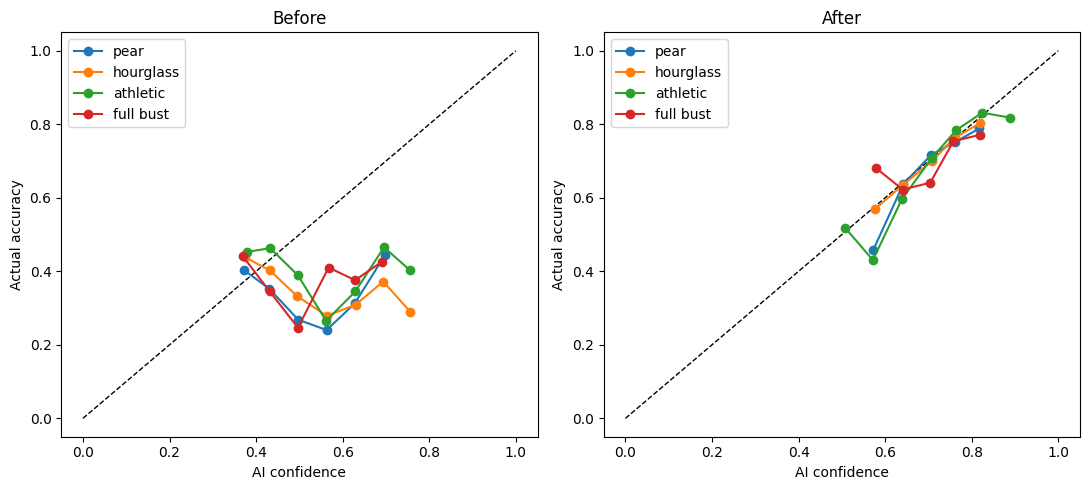

In [ ]:
# ── 13. 보정 전후 비교 ──
qcols = ['q_small', 'q_fit', 'q_large']

# 체형별 ECE 보정 전 / 보정 후
res = pt.groupby('body_type').apply(lambda d: pd.Series({
    '사람수': d['user_id'].nunique(),
    'ECE_보정전': ece(d[pcols].values, d['label'].values),
    'ECE_보정후': ece(d[qcols].values, d['label'].values)})).round(3)
res.loc['전체'] = [pt['user_id'].nunique(),
                   ece(pt[pcols].values, pt['label'].values),
                   ece(pt[qcols].values, pt['label'].values)]
display(res.sort_values('ECE_보정후'))

# 신뢰도 그래프: 대각선에 가까울수록 정직한 AI
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, cols, title in [(axes[0], pcols, 'Before'), (axes[1], qcols, 'After')]:
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    for bt in ['pear', 'hourglass', 'athletic', 'full bust']:
        d = pt[pt['body_type'] == bt]
        xs, ys = reliability(d[cols].values, d['label'].values)
        ax.plot(xs, ys, marker='o', label=bt)
    ax.set_title(title); ax.set_xlabel('AI confidence'); ax.set_ylabel('Actual accuracy')
    ax.legend()
plt.tight_layout(); plt.show()

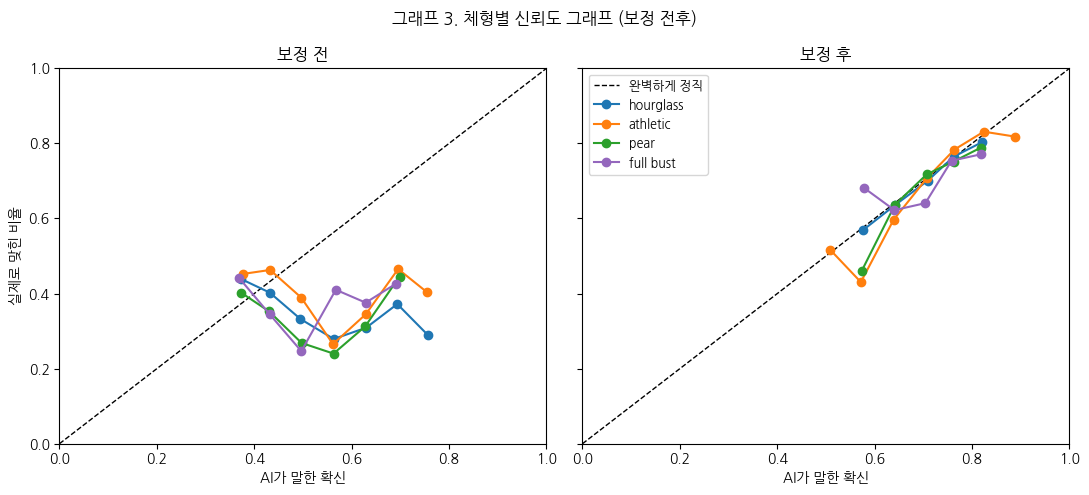

In [ ]:
# ── 그래프 3: 보정 전후 신뢰도 그래프 ──
# 점선(대각선)에 가까울수록 AI가 정직하게 말한다는 뜻
# 선이 대각선 아래 = AI가 실제보다 자신만만, 위 = 실제보다 자신 없음
colors = dict(zip(order, plt.cm.tab10.colors))   # 체형별 색 고정

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, cols, title in [(axes[0], pcols, '보정 전'), (axes[1], qcols, '보정 후')]:
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='완벽하게 정직')
    for bt in ['hourglass', 'athletic', 'pear', 'full bust']:
        d = pt[pt['body_type'] == bt]
        xs, ys = reliability(d[cols].values, d['label'].values)
        ax.plot(xs, ys, marker='o', color=colors[bt], label=bt)
    ax.set_title(title); ax.set_xlabel('AI가 말한 확신')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].set_ylabel('실제로 맞힌 비율'); axes[1].legend(fontsize=9)
fig.suptitle('그래프 3. 체형별 신뢰도 그래프 (보정 전후)')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프3.png", dpi=300); plt.show()

## 3-5. '작음'·'큼' 확률이 각각 정직한지 확인

앞의 ECE는 AI가 **고른 답**만 보고 정직한지 매긴다.
그런데 보정 후 AI는 대부분 "맞음"을 고르기 때문에, 사실상 "맞음"이 정직한지만 확인한 셈이다.

이 연구에서 중요한 건 **"작을 거예요", "클 거예요"라는 말이 정직한지**다.
그래서 작음·큼 확률을 따로 떼서, AI가 말한 확률과 실제 비율이 맞는지 체형별로 확인한다.

In [ ]:
# ── 14. 작음·큼 확률이 각각 정직한지 확인 (체형별) ──
# AI가 "작을 확률 x%"라고 했을 때 실제로 x%가 작았는지 (큼도 똑같이)
def class_ece(q, y, k, n_bins=10):
    # q: AI가 말한 그 결과의 확률, k: 확인할 결과 (0=작음, 2=큼)
    actual = (y == k)
    bins = np.linspace(0, q.max(), n_bins + 1)
    total = 0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (q > lo) & (q <= hi)
        if m.sum() > 0:
            # 이 구간에서 "말한 확률"과 "실제 비율"의 차이 × 구간 비중
            total += abs(q[m].mean() - actual[m].mean()) * m.mean()
    return total

res2 = pt.groupby('body_type')[['q_small', 'q_large', 'label']].apply(lambda d: pd.Series({
    '말한 작음 확률': d['q_small'].mean(),
    '실제 작음 비율': (d['label'] == 0).mean(),
    '작음 ECE': class_ece(d['q_small'].values, d['label'].values, 0),
    '말한 큼 확률': d['q_large'].mean(),
    '실제 큼 비율': (d['label'] == 2).mean(),
    '큼 ECE': class_ece(d['q_large'].values, d['label'].values, 2)})).round(3)
display(res2.sort_values('작음 ECE'))

,말한 작음 확률,실제 작음 비율,작음 ECE,말한 큼 확률,실제 큼 비율,큼 ECE
body_type,,,,,,
hourglass,0.133,0.134,0.009,0.127,0.131,0.007
pear,0.132,0.125,0.012,0.139,0.152,0.015
full bust,0.145,0.135,0.013,0.131,0.171,0.039
athletic,0.136,0.134,0.016,0.120,0.120,0.003
petite,0.124,0.128,0.016,0.129,0.141,0.014
straight & narrow,0.133,0.129,0.018,0.121,0.115,0.007
apple,0.158,0.154,0.024,0.126,0.122,0.017


- **작음**: 모든 체형에서 AI가 예상한 것과 실제가 거의 같다. → 정직하다.
- **큼**: full bust만 AI 예상(13.1%)보다 실제(17.1%)가 훨씬 많다. → **큰 옷을 덜 예상**한다.
- pear는 AI 예상이 정확한데도 작은 옷을 덜 맞힌다. → AI가 틀리게 말하는 게 아니라, **누가 작을지 잘 구별하지 못하는 것**이다.

In [ ]:
# ── 15. AI가 누가 작을지 얼마나 잘 구별하는지 (AUC, 체형별) ──
# AUC: 실제로 작았던 사람과 아니었던 사람을 하나씩 뽑았을 때,
#      AI가 작았던 사람에게 더 높은 '작음 확률'을 줄 확률
#      0.5 = 동전 던지기 수준(구별 못 함), 1.0 = 완벽하게 구별
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)
rows = []
for bt, d in pt.groupby('body_type'):
    y_s = (d['label'] == 0).astype(int).values   # 실제 작음이면 1
    y_l = (d['label'] == 2).astype(int).values   # 실제 큼이면 1
    auc_s = roc_auc_score(y_s, d['q_small'])
    auc_l = roc_auc_score(y_l, d['q_large'])

    # 오차 범위: 사람 단위로 1000번 다시 뽑아 AUC 재계산
    users = d['user_id'].unique()
    idx = d.groupby('user_id').indices
    bs_s, bs_l = [], []
    for _ in range(1000):
        pick = rng.choice(users, len(users), replace=True)
        ii = np.concatenate([idx[u] for u in pick])
        bs_s.append(roc_auc_score(y_s[ii], d['q_small'].values[ii]))
        bs_l.append(roc_auc_score(y_l[ii], d['q_large'].values[ii]))

    rows.append({'body_type': bt,
                 '작음 AUC': auc_s,
                 '작음 하한': np.percentile(bs_s, 2.5), '작음 상한': np.percentile(bs_s, 97.5),
                 '큼 AUC': auc_l,
                 '큼 하한': np.percentile(bs_l, 2.5), '큼 상한': np.percentile(bs_l, 97.5)})

auc_df = pd.DataFrame(rows).set_index('body_type').round(3)
display(auc_df.sort_values('작음 AUC'))

,작음 AUC,작음 하한,작음 상한,큼 AUC,큼 하한,큼 상한
body_type,,,,,,
apple,0.636,0.588,0.682,0.633,0.571,0.692
pear,0.667,0.642,0.691,0.635,0.612,0.660
full bust,0.673,0.618,0.723,0.712,0.619,0.782
hourglass,0.675,0.659,0.689,0.634,0.617,0.649
straight & narrow,0.700,0.671,0.730,0.647,0.615,0.680
athletic,0.713,0.697,0.731,0.653,0.635,0.671
petite,0.714,0.690,0.738,0.617,0.592,0.641


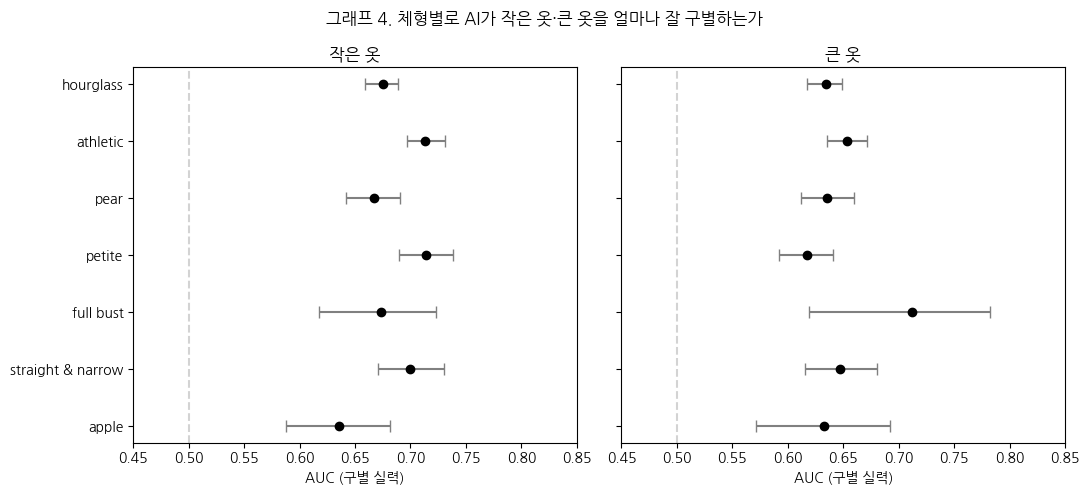

In [ ]:
# ── 그래프 4: 체형별 구별 실력 (AUC) + 95% 오차 범위 ──
FIG_DIR = f"{BASE}/그래프"
os.makedirs(FIG_DIR, exist_ok=True)
order = ['hourglass', 'athletic', 'pear', 'petite', 'full bust', 'straight & narrow', 'apple']

# 점 = AUC, 가로선 = 오차 범위. 0.5 점선은 '동전 던지기 수준'
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
a = auc_df.loc[order]
y = np.arange(len(order))
for ax, col, lo, hi, title in [(axes[0], '작음 AUC', '작음 하한', '작음 상한', '작은 옷'),
                               (axes[1], '큼 AUC', '큼 하한', '큼 상한', '큰 옷')]:
    ax.errorbar(a[col], y, xerr=[a[col] - a[lo], a[hi] - a[col]],
                fmt='o', color='black', ecolor='gray', capsize=4)
    ax.axvline(0.5, ls='--', color='lightgray')
    ax.set_xlim(0.45, 0.85); ax.set_title(title); ax.set_xlabel('AUC (구별 실력)')
axes[0].set_yticks(y); axes[0].set_yticklabels(order)
axes[0].invert_yaxis()
fig.suptitle('그래프 4. 체형별로 AI가 작은 옷·큰 옷을 얼마나 잘 구별하는가')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프4.png", dpi=300); plt.show()

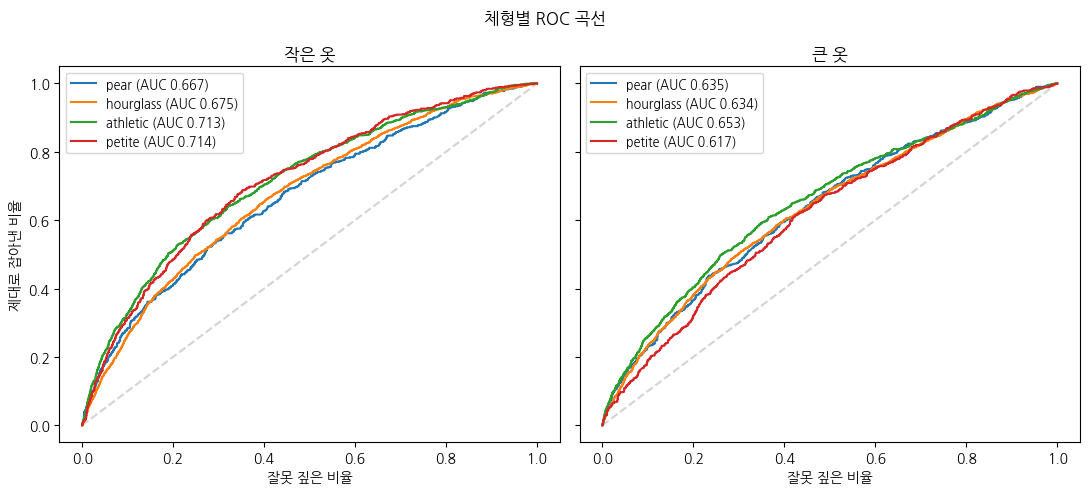

In [ ]:
# ── ROC 곡선: 체형별로 AI가 작은 옷을 얼마나 잘 구별하는지 ──
# 왼쪽 위로 많이 휠수록 구별을 잘함. 대각선은 동전 던지기 수준
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, k, col, title in [(axes[0], 0, 'q_small', '작은 옷'), (axes[1], 2, 'q_large', '큰 옷')]:
    ax.plot([0, 1], [0, 1], '--', color='lightgray')
    for bt in ['pear', 'hourglass', 'athletic', 'petite']:
        d = pt[pt['body_type'] == bt]
        fpr, tpr, _ = roc_curve((d['label'] == k).astype(int), d[col])
        auc = auc_df.loc[bt, '작음 AUC' if k == 0 else '큼 AUC']
        ax.plot(fpr, tpr, label=f"{bt} (AUC {auc:.3f})")
    ax.set_title(title); ax.set_xlabel('잘못 짚은 비율'); ax.legend(fontsize=9)
axes[0].set_ylabel('제대로 잡아낸 비율')
fig.suptitle('체형별 ROC 곡선')
plt.tight_layout(); plt.show()

- AUC는 0.5면 구별 못 함, 1이면 완벽하게 구별. 모든 체형이 0.62~0.71로 AI의 구별 실력은 높지 않다.
- **작은 옷**: pear는 athletic·petite보다 범위가 낮고 겹치지 않는다. → AI는 pear 고객 중 **누가 작을지 덜 구별한다.**
- 다만 hourglass(0.675)와는 비슷해, pear만 유독 낮은 것은 아니다.
- **큰 옷**: 체형끼리 범위가 대부분 겹쳐 차이가 뚜렷하지 않다.

> 앞의 결과와 합치면, pear는 AI 예상이 평균적으로는 맞지만, 한 명 한 명을 구별하는 실력이 athletic·petite보다 상대적으로 낮아 작은 옷을 놓친다.

## 4. Conformal Prediction을 활용한 체형별 공정성 보정

**출처**: Zaffran, M., Féron, O., Goude, Y., Josse, J., & Dieuleveut, A. (2022). Adaptive Conformal Predictions for Time Series. *ICML 2022*.

**방법 개요**
Conformal Prediction은 단일 답 대신 후보 집합을 제시하고, 정답이 그 집합에 포함될 확률을 일정 수준(본 연구에서는 90%)으로 보장하는 방법이다. 원 논문은 시계열 예측에서 시간에 따라 기준을 조정했으며, 본 연구는 이를 체형에 따라 기준을 달리 설정하는 방식으로 적용하였다.

| 구분 | 원 논문 | 본 연구 |
| --- | --- | --- |
| 예측 대상 | 시계열 수치 | 사이즈 적합도 (작음·맞음·큼) |
| 출력 형태 | 예측 구간 | 후보 집합 (예: {작음, 맞음}) |
| 기준 조정 단위 | 시간 | 체형 |
| 목표 포함률 | 90% | 90% |

**작동 방식**
- 모델이 확실한 경우 후보 하나, 불확실한 경우 후보 여러 개를 제시한다.
- 후보 포함 여부를 결정하는 기준값은 보정용 데이터로만 산출한다.

**비교 설계**
1. **공통 기준**: 모든 체형에 동일한 기준값을 적용한다.
2. **체형별 기준**: 체형마다 기준값을 따로 산출한다 (Mondrian Conformal Prediction).

두 방식에서 체형별 정답 포함률과 평균 후보 수를 비교하여, 체형별 기준이 모든 체형에 동일한 신뢰 수준을 보장하는지 확인한다.

In [ ]:
# ── 17. conformal: 기준값 구하기 ──
# 목표: 정답이 후보 묶음 안에 90% 들어가게 (alpha = 0.1)
alpha = 0.1

# 보정용에도 시험용과 똑같은 방식으로 보정한 확률을 만듦
q_cal = softmax((pc[zcols].values + log_prior) / T, axis=1)
q_test = pt[qcols].values
y_cal, y_test = pc['label'].values, pt['label'].values

# '얼마나 빗나갔나' 점수 = 1 - AI가 실제 정답에 준 확률
# 정답에 높은 확률을 줬으면 점수가 작고, 낮은 확률을 줬으면 점수가 큼
score_cal = 1 - q_cal[np.arange(len(y_cal)), y_cal]

def threshold(scores, alpha):
    # 보정용 점수를 줄 세워 90% 지점의 값을 기준값으로 씀
    # (n+1) 보정은 표본 수가 유한할 때도 90% 보장을 지키기 위한 장치
    n = len(scores)
    level = min(1, np.ceil((n + 1) * (1 - alpha)) / n)
    return np.quantile(scores, level, method='higher')

# [방법 1] 공통 기준: 모든 체형에 기준값 하나
t_all = threshold(score_cal, alpha)

# [방법 2] 체형별 기준: 체형마다 보정용 데이터로 기준값을 따로 구함
t_bt = {bt: threshold(score_cal[pc['body_type'].values == bt], alpha)
        for bt in order}

print("공통 기준값:", round(t_all, 3))
display(pd.Series(t_bt, name='체형별 기준값').round(3))

공통 기준값: 0.871


,체형별 기준값
hourglass,0.875
athletic,0.871
pear,0.865
petite,0.867
full bust,0.870
straight & narrow,0.870
apple,0.878


In [ ]:
# ── 18. 후보 묶음 만들고 두 방법 비교 ──
# 후보에 넣는 규칙: (1 - AI가 그 답에 준 확률) ≤ 기준값
#   → 기준값이 클수록 확률이 낮은 답까지 후보에 들어가 후보가 많아짐
set_all = (1 - q_test) <= t_all
t_row = pt['body_type'].map(t_bt).values[:, None]
set_bt = (1 - q_test) <= t_row

def evaluate(sets, name):
    covered = sets[np.arange(len(y_test)), y_test]   # 정답이 후보 안에 있는지
    size = sets.sum(axis=1)                            # 후보 개수 (1~3개)
    d = pd.DataFrame({'body_type': pt['body_type'].values, 'covered': covered, 'size': size})
    out = d.groupby('body_type').agg(포함률=('covered', 'mean'), 평균후보수=('size', 'mean'))
    out.loc['전체'] = [covered.mean(), size.mean()]
    return out.add_prefix(f'{name}_')

conf = evaluate(set_all, '공통').join(evaluate(set_bt, '체형별')).round(3)
display(conf.loc[order + ['전체']])

,공통_포함률,공통_평균후보수,체형별_포함률,체형별_평균후보수
body_type,,,,
hourglass,0.898,1.837,0.905,1.890
athletic,0.904,1.772,0.905,1.777
pear,0.896,1.888,0.885,1.808
petite,0.904,1.840,0.896,1.799
full bust,0.901,1.892,0.900,1.889
straight & narrow,0.906,1.770,0.905,1.763
apple,0.908,1.986,0.918,2.068
전체,0.901,1.832,0.901,1.836


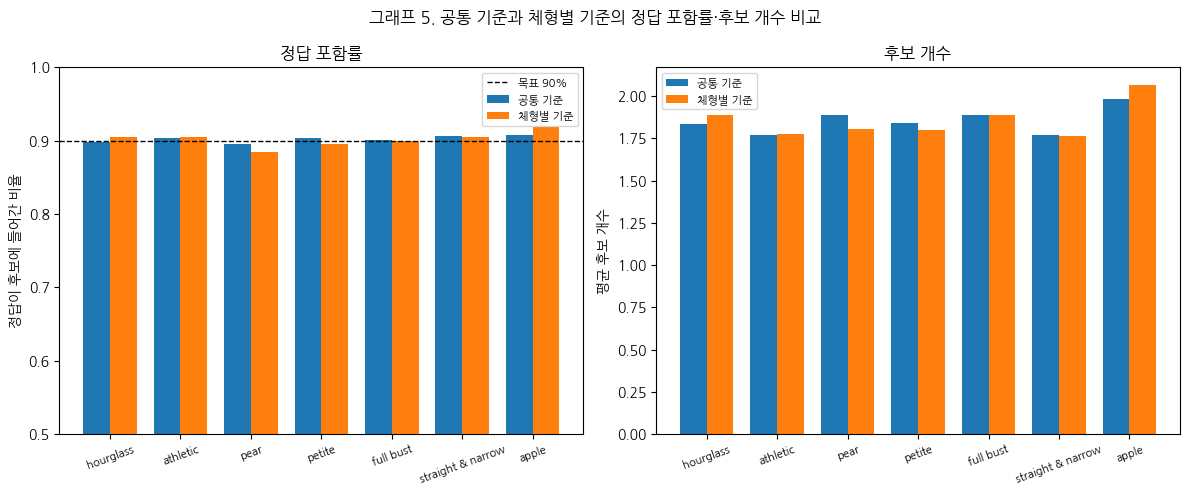

In [ ]:
# ── 그래프 5: 공통 기준 vs 체형별 기준 ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(len(order)); w = 0.38
c = conf.loc[order]

# 왼쪽: 정답 포함률 (점선 = 목표 90%)
axes[0].bar(x - w/2, c['공통_포함률'], w, label='공통 기준')
axes[0].bar(x + w/2, c['체형별_포함률'], w, label='체형별 기준')
axes[0].axhline(1 - alpha, ls='--', color='black', lw=1, label='목표 90%')
axes[0].set_ylim(0.5, 1); axes[0].set_ylabel('정답이 후보에 들어간 비율')
axes[0].set_title('정답 포함률')

# 오른쪽: 평균 후보 개수 (많을수록 AI가 헷갈린다는 뜻)
axes[1].bar(x - w/2, c['공통_평균후보수'], w, label='공통 기준')
axes[1].bar(x + w/2, c['체형별_평균후보수'], w, label='체형별 기준')
axes[1].set_ylabel('평균 후보 개수'); axes[1].set_title('후보 개수')

for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(order, fontsize=8, rotation=20); ax.legend(fontsize=8)
fig.suptitle('그래프 5. 공통 기준과 체형별 기준의 정답 포함률·후보 개수 비교')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프5.png", dpi=300); plt.show()

**결과: 전체로 보면 약속을 지킨 것처럼 보인다**

공통 기준만으로도 모든 체형의 정답 포함률이 90% 근처(89.6~90.8%)다.
체형별 기준으로 바꿔도 거의 차이가 없다.

→ 겉으로는 모든 체형이 똑같이 90%를 보장받는 것처럼 보인다.

In [ ]:
# ── 19. 실제 결과별로 나눠서 포함률 보기 ──
# 실제로 작았던 옷 / 맞았던 옷 / 컸던 옷마다 정답이 후보에 들어간 비율
def coverage_by_label(sets, name):
    covered = sets[np.arange(len(y_test)), y_test]
    d = pd.DataFrame({'body_type': pt['body_type'].values, 'label': y_test, 'covered': covered})
    t = d.pivot_table(index='body_type', columns='label', values='covered', aggfunc='mean')
    t.columns = [f'{name}_작음', f'{name}_맞음', f'{name}_큼']
    return t

cov_label = coverage_by_label(set_all, '공통').round(3)
display(cov_label.loc[order])

,공통_작음,공통_맞음,공통_큼
body_type,,,
hourglass,0.684,1.0,0.542
athletic,0.698,1.0,0.539
pear,0.640,1.0,0.611
petite,0.677,1.0,0.615
full bust,0.743,1.0,0.623
straight & narrow,0.674,1.0,0.550
apple,0.789,1.0,0.508


**결과: 옷 결과별로 나눠 보면 약속이 지켜지지 않는다**

| 실제 결과 | 정답 포함률 |
| --- | --- |
| 맞았던 옷 | 100% |
| 작았던 옷 | 64 ~ 79% |
| 컸던 옷 | 51 ~ 62% |

- AI가 거의 항상 "맞음"을 후보에 넣어, 맞는 옷은 모두 포함된다.
- 맞는 옷이 전체의 74%라 평균이 90%처럼 보였을 뿐이다.
- 반품이 생기는 **작은 옷·큰 옷에서는 90%에 크게 못 미친다.**
- 작은 옷에서는 **pear가 64%로 가장 낮다.**

→ 전체 평균만 보면 공평해 보이지만, 실제로는 pear 고객이 가장 손해를 본다.

In [ ]:
# ── 20. 체형 × 결과별 기준으로 고치기 ──
# 보정용에서 "배형이면서 실제 작았던 옷"처럼 칸마다 기준값을 따로 구함
# 시험 때는 각 답(작음·맞음·큼)마다 그 체형의 그 답 기준값과 비교해 후보에 넣음
bt_cal = pc['body_type'].values
t_bk = {}
for bt in order:
    for k in [0, 1, 2]:
        m = (bt_cal == bt) & (y_cal == k)
        # 그 칸에서 "1 - 정답에 준 확률" 점수들로 90% 기준값을 구함
        t_bk[(bt, k)] = threshold(1 - q_cal[m, k], alpha)

# 시험용 각 리뷰에 대해 답마다 해당 기준값을 붙임
bt_test = pt['body_type'].values
t_mat = np.array([[t_bk[(bt, k)] for k in [0, 1, 2]] for bt in bt_test])
set_bk = (1 - q_test) <= t_mat

# 결과별 포함률 비교: 공통 기준 vs 체형×결과별 기준
cmp_label = coverage_by_label(set_all, '공통').join(
    coverage_by_label(set_bk, '체형결과별')).round(3)
display(cmp_label.loc[order])

# 평균 후보 수도 같이 확인 (약속을 지키는 대가로 후보가 얼마나 늘어나는지)
size_cmp = pd.DataFrame({
    '공통_후보수': pd.Series(set_all.sum(1)).groupby(bt_test).mean(),
    '체형결과별_후보수': pd.Series(set_bk.sum(1)).groupby(bt_test).mean()}).round(3)
display(size_cmp.loc[order])

,공통_작음,공통_맞음,공통_큼,체형결과별_작음,체형결과별_맞음,체형결과별_큼
body_type,,,,,,
hourglass,0.684,1.0,0.542,0.923,0.909,0.897
athletic,0.698,1.0,0.539,0.909,0.906,0.866
pear,0.640,1.0,0.611,0.901,0.904,0.873
petite,0.677,1.0,0.615,0.923,0.916,0.885
full bust,0.743,1.0,0.623,0.906,0.906,0.957
straight & narrow,0.674,1.0,0.550,0.929,0.909,0.918
apple,0.789,1.0,0.508,0.974,0.887,0.900


,공통_후보수,체형결과별_후보수
hourglass,1.837,2.505
athletic,1.772,2.401
pear,1.888,2.454
petite,1.840,2.459
full bust,1.892,2.519
straight & narrow,1.770,2.493
apple,1.986,2.625


**결과: 체형 × 결과별 기준 적용**

| 체형 | 작은 옷 포함률 (공통 → 체형×결과별) | 큰 옷 포함률 (공통 → 체형×결과별) | 평균 후보 수 (공통 → 체형×결과별) |
| --- | --- | --- | --- |
| hourglass | 68.4% → 92.3% | 54.2% → 89.7% | 1.84 → 2.51 |
| athletic | 69.8% → 90.9% | 53.9% → 86.6% | 1.77 → 2.40 |
| pear | **64.0% → 90.1%** | 61.1% → 87.3% | 1.89 → 2.45 |
| petite | 67.7% → 92.3% | 61.5% → 88.5% | 1.84 → 2.46 |
| full bust | 74.3% → 90.6% | 62.3% → 95.7% | 1.89 → 2.52 |
| straight & narrow | 67.4% → 92.9% | 55.0% → 91.8% | 1.77 → 2.49 |
| apple | 78.9% → 97.4% | 50.8% → 90.0% | 1.99 → 2.63 |

**좋아진 점**
- pear의 작은 옷 포함률이 64% → 90%로 올라왔다.
- 모든 체형이 작은 옷·큰 옷 모두 87~97%로, 목표 90% 근처에 맞춰졌다.
- 전체 평균뿐 아니라 **반품이 생기는 옷에서도 모든 체형이 비슷하게 보장**받는다.

**대가**
- 평균 후보 수가 1.8개 → 2.5개로 늘었다.
- 답이 세 개뿐인데 평균 2.5개를 제시한다는 것은, "작거나 맞거나 클 거예요"처럼 **거의 모든 답을 내놓는 경우가 많다**는 뜻이다.
- 약속은 지키지만, 고객에게는 실질적인 도움이 적은 답이 된다.

In [ ]:
# ── 21. 목표 포함률별 후보 수 비교 (90% vs 80%) ──
def make_sets(alpha):
    # 체형×결과별 기준값을 주어진 alpha로 다시 계산해서 후보 묶음 생성
    t = {(bt, k): threshold(1 - q_cal[(bt_cal == bt) & (y_cal == k), k], alpha)
         for bt in order for k in [0, 1, 2]}
    tm = np.array([[t[(bt, k)] for k in [0, 1, 2]] for bt in bt_test])
    return (1 - q_test) <= tm

rows = []
for a in [0.1, 0.2]:
    s = make_sets(a)
    cov = coverage_by_label(s, '').loc[order]
    rows.append(pd.DataFrame({
        '목표': f'{int((1-a)*100)}%',
        '작음 포함률': cov['_작음'], '큼 포함률': cov['_큼'],
        '평균 후보수': pd.Series(s.sum(1)).groupby(bt_test).mean().loc[order]}))
display(pd.concat(rows).round(3))

,목표,작음 포함률,큼 포함률,평균 후보수
hourglass,90%,0.923,0.897,2.505
athletic,90%,0.909,0.866,2.401
pear,90%,0.901,0.873,2.454
petite,90%,0.923,0.885,2.459
full bust,90%,0.906,0.957,2.519
straight & narrow,90%,0.929,0.918,2.493
apple,90%,0.974,0.900,2.625
hourglass,80%,0.820,0.777,2.096
athletic,80%,0.812,0.761,1.941
pear,80%,0.801,0.749,2.019


In [ ]:
# ── 22. 옷 정보(item_id 기반 특성) 만들기 ──
from sklearn.model_selection import GroupKFold

m = 20   # 리뷰가 적은 옷은 전체 평균 쪽으로 당겨서 값이 튀지 않게 함
prior_s = (train['label'] == 0).mean()
prior_l = (train['label'] == 2).mean()

def item_stats(src):
    # 옷마다 작음·큼 비율(보정값)과 평균 사이즈, 리뷰 수를 계산
    gi = src.groupby('item_id').agg(n=('label', 'size'),
                                     s=('label', lambda x: (x == 0).sum()),
                                     l=('label', lambda x: (x == 2).sum()),
                                     size_mean=('size', 'mean'))
    gi['item_small'] = (gi['s'] + m * prior_s) / (gi['n'] + m)
    gi['item_large'] = (gi['l'] + m * prior_l) / (gi['n'] + m)
    gi['item_n'] = gi['n']
    return gi[['item_small', 'item_large', 'size_mean', 'item_n']]

def add_item_feats(df, stats):
    out = df.join(stats, on='item_id')
    # 처음 보는 옷은 전체 평균으로 채움
    out['item_small'] = out['item_small'].fillna(prior_s)
    out['item_large'] = out['item_large'].fillna(prior_l)
    out['item_n'] = out['item_n'].fillna(0)
    # 이 사람이 빌린 사이즈가 그 옷의 평균 사이즈보다 얼마나 큰지
    out['size_diff'] = out['size'] - out['size_mean']
    return out.drop(columns='size_mean')

# 학습용: 사람 단위 5등분, 각 덩어리는 나머지로 계산한 값 사용 (정답 미리 보기 방지)
parts = []
for tr_idx, va_idx in GroupKFold(n_splits=5).split(train, groups=train['user_id']):
    stats = item_stats(train.iloc[tr_idx])
    parts.append(add_item_feats(train.iloc[va_idx], stats))
train2 = pd.concat(parts).loc[train.index]

# 보정용·시험용: 학습용 전체로 계산한 값 사용
stats_all = item_stats(train)
cal2 = add_item_feats(cal, stats_all)
test2 = add_item_feats(test, stats_all)

features2 = features + ['item_small', 'item_large', 'item_n', 'size_diff']
print(train2[features2].head())

   height_cm  weight_kg  bust_band  cup_num  body_type category  size   age  \
2     165.10    61.2360       34.0      3.0       pear    dress     8  34.0   
3     175.26    65.7720       34.0      2.0   athletic     gown    12  27.0   
5     160.02    50.8032       34.0      3.0  hourglass    dress     4  27.0   
7     167.64        NaN       36.0      4.0  full bust     gown    21  27.0   
8     160.02    51.7104       32.0      2.0     petite     gown     1  33.0   

   item_small  item_large  item_n  size_diff  
2    0.049403    0.190778  1026.0  -8.741715  
3    0.052514    0.050765    50.0   0.940000  
5    0.127429    0.121596     1.0 -22.000000  
7    0.140753    0.042555   134.0   6.985075  
8    0.137840    0.030357   130.0 -12.223077  


In [ ]:
# 지금 결과를 재현할 수 있게 덩어리 배정과 라이브러리 버전 저장
import sklearn, lightgbm
fold_map = []
for f, (_, va_idx) in enumerate(GroupKFold(n_splits=5).split(train, groups=train['user_id'])):
    fold_map.append(pd.DataFrame({'user_id': train.iloc[va_idx]['user_id'].unique(), 'fold': f}))
pd.concat(fold_map).to_csv(f"{BASE}/데이터/정리/학습용_fold배정.csv", index=False)

with open(f"{BASE}/결과표/v2/버전.txt", 'w') as fp:
    fp.write(f"scikit-learn {sklearn.__version__}\nlightgbm {lightgbm.__version__}\npandas {pd.__version__}\nnumpy {np.__version__}\n")
print("저장 완료")

저장 완료


In [ ]:
# ── 23. 옷 정보를 넣어 다시 학습 ──
tr2 = train2[~train2['user_id'].isin(val_users)]
val2 = train2[train2['user_id'].isin(val_users)]
val_w2 = compute_sample_weight('balanced', val2['label'])

model2 = lgb.LGBMClassifier(objective='multiclass', n_estimators=3000, learning_rate=0.1,
                            num_leaves=31, class_weight='balanced', random_state=42, verbose=-1)
model2.fit(tr2[features2], tr2['label'],
           eval_set=[(val2[features2], val2['label'])], eval_sample_weight=[val_w2],
           callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])
print("사용된 나무 수:", model2.best_iteration_)

# 구별 실력 비교: 옷 정보 없을 때 vs 있을 때 (시험용 전체 AUC)
p_old = model.predict_proba(test[features])
p_new = model2.predict_proba(test2[features2])
for k, name in [(0, '작음'), (2, '큼')]:
    print(name, "AUC  기존:", round(roc_auc_score(test['label'] == k, p_old[:, k]), 3),
          " → 옷 정보 추가:", round(roc_auc_score(test2['label'] == k, p_new[:, k]), 3))

Training until validation scores don't improve for 50 rounds
[100]	valid_0's multi_logloss: 0.838947
Early stopping, best iteration is:
[64]	valid_0's multi_logloss: 0.837546
사용된 나무 수: 64
작음 AUC  기존: 0.69  → 옷 정보 추가: 0.795
큼 AUC  기존: 0.646  → 옷 정보 추가: 0.798


In [ ]:
# ── 24. 새 모델(옷 정보 포함)로 예측 결과 저장 ──
def save_preds_v2(df, name):
    prob = model2.predict_proba(df[features2])
    raw = model2.predict(df[features2], raw_score=True)
    out = df[['review_id', 'user_id', 'body_type', 'height_cm', 'weight_kg', 'label']].copy()
    out['p_small'], out['p_fit'], out['p_large'] = prob[:, 0], prob[:, 1], prob[:, 2]
    out['z_small'], out['z_fit'], out['z_large'] = raw[:, 0], raw[:, 1], raw[:, 2]
    save_path = f"{PRED_DIR}/{name}_예측확률_v2.csv"
    out.to_csv(save_path, index=False)
    print(save_path, "저장 완료:", len(out), "줄")

save_preds_v2(cal2, '보정용')
save_preds_v2(test2, '시험용')

/content/drive/MyDrive/3-2/시각화 학술제/예측결과/보정용_예측확률_v2.csv 저장 완료: 35696 줄
/content/drive/MyDrive/3-2/시각화 학술제/예측결과/시험용_예측확률_v2.csv 저장 완료: 36021 줄


In [ ]:
# ── A. 준비: 라이브러리, 경로, 파일 불러오기 ──
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.special import softmax
from sklearn.metrics import roc_auc_score

BASE = "/content/drive/MyDrive/3-2/시각화 학술제"
PRED_DIR = f"{BASE}/예측결과"
FIG_DIR = f"{BASE}/그래프/v2"
os.makedirs(FIG_DIR, exist_ok=True)

# 새 모델(옷 정보 포함)의 예측 파일
pt = pd.read_csv(f"{PRED_DIR}/시험용_예측확률_v2.csv")   # 시험용
pc = pd.read_csv(f"{PRED_DIR}/보정용_예측확률_v2.csv")   # 보정용

# 학습용 정답 비율 (확률 보정에 필요)
data = pd.read_csv(f"{BASE}/데이터/정리/정리데이터.csv", keep_default_na=False, na_values=[''])
split = pd.read_csv(f"{BASE}/데이터/정리/분할명단.csv")
train_label = data.merge(split, on='user_id').query("set == 'train'")['label']

# 모든 표·그래프에서 체형 순서 고정
order = ['hourglass', 'athletic', 'pear', 'petite', 'full bust', 'straight & narrow', 'apple']
colors = dict(zip(order, plt.cm.tab10.colors))
pcols, zcols, qcols = ['p_small', 'p_fit', 'p_large'], ['z_small', 'z_fit', 'z_large'], ['q_small', 'q_fit', 'q_large']
rng = np.random.default_rng(42)

print(len(pt), len(pc))   # 36021 35696

36021 35696


,사람수,실제작음,작음_재현율,실제큼,큼_재현율,작음_하한,작음_상한,큼_하한,큼_상한
body_type,,,,,,,,,
hourglass,5975,1490,0.654,1456,0.696,0.628,0.678,0.672,0.720
athletic,4689,1145,0.690,1026,0.645,0.662,0.718,0.612,0.679
pear,2442,584,0.644,710,0.713,0.607,0.681,0.678,0.746
petite,2416,570,0.635,628,0.648,0.591,0.676,0.610,0.685
full bust,1642,459,0.704,579,0.746,0.664,0.743,0.668,0.794
straight & narrow,1505,368,0.677,329,0.663,0.628,0.725,0.614,0.710
apple,536,152,0.704,120,0.758,0.629,0.782,0.689,0.829


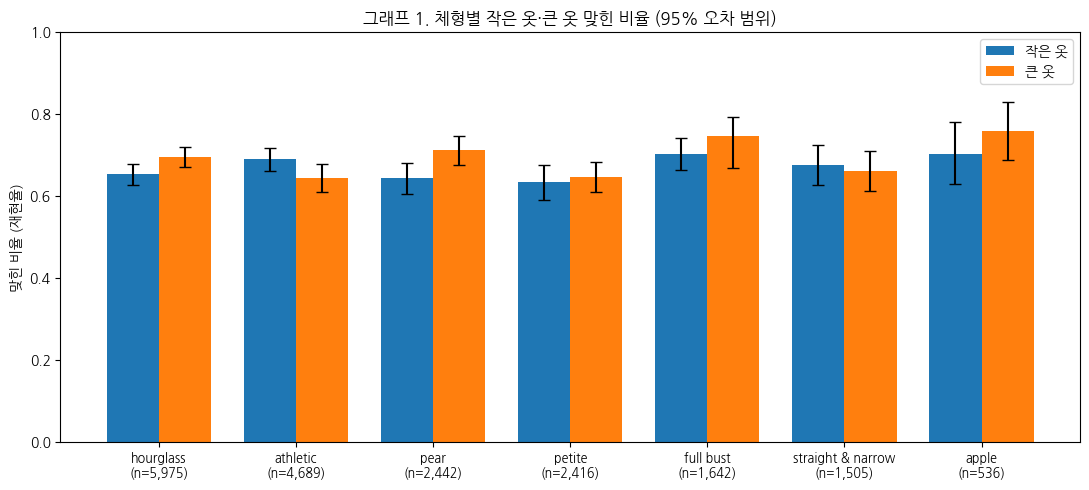

In [ ]:
# ── B. 체형별 작은 옷·큰 옷 맞힌 비율 + 오차 범위 ──
# 세 확률 중 가장 큰 것을 AI의 답으로 봄 (0=작음, 1=맞음, 2=큼)
pt['pred'] = pt[pcols].values.argmax(axis=1)
pt['is_small'] = (pt['label'] == 0).astype(int)
pt['hit_small'] = ((pt['label'] == 0) & (pt['pred'] == 0)).astype(int)
pt['is_large'] = (pt['label'] == 2).astype(int)
pt['hit_large'] = ((pt['label'] == 2) & (pt['pred'] == 2)).astype(int)

# 체형별 재현율
g = pt.groupby('body_type').agg(
    사람수=('user_id', 'nunique'),
    실제작음=('is_small', 'sum'), 맞힌작음=('hit_small', 'sum'),
    실제큼=('is_large', 'sum'), 맞힌큼=('hit_large', 'sum'))
g['작음_재현율'] = g['맞힌작음'] / g['실제작음']
g['큼_재현율'] = g['맞힌큼'] / g['실제큼']

# 오차 범위: 사람 단위로 1000번 다시 뽑아 재현율 재계산, 가운데 95% 범위
per_user = pt.groupby(['body_type', 'user_id'])[['is_small', 'hit_small', 'is_large', 'hit_large']].sum().reset_index()
ci = {}
for bt, d in per_user.groupby('body_type'):
    arr = d[['is_small', 'hit_small', 'is_large', 'hit_large']].values
    n = len(arr); rs, rl = [], []
    for _ in range(1000):
        s = arr[rng.integers(0, n, n)].sum(axis=0)
        rs.append(s[1] / s[0]); rl.append(s[3] / s[2])
    ci[bt] = {'작음_하한': np.percentile(rs, 2.5), '작음_상한': np.percentile(rs, 97.5),
              '큼_하한': np.percentile(rl, 2.5), '큼_상한': np.percentile(rl, 97.5)}

result = g[['사람수', '실제작음', '작음_재현율', '실제큼', '큼_재현율']].join(pd.DataFrame(ci).T).loc[order]
display(result.round(3))

# 그래프 1
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(order)); w = 0.38
labels = [f"{bt}\n(n={int(result.loc[bt, '사람수']):,})" for bt in order]
ax.bar(x - w/2, result['작음_재현율'], w, label='작은 옷',
       yerr=[result['작음_재현율'] - result['작음_하한'], result['작음_상한'] - result['작음_재현율']], capsize=4)
ax.bar(x + w/2, result['큼_재현율'], w, label='큰 옷',
       yerr=[result['큼_재현율'] - result['큼_하한'], result['큼_상한'] - result['큼_재현율']], capsize=4)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('맞힌 비율 (재현율)'); ax.set_ylim(0, 1); ax.legend()
ax.set_title('그래프 1. 체형별 작은 옷·큰 옷 맞힌 비율 (95% 오차 범위)')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프1.png", dpi=300); plt.show()

## 5-1. 새 모델(옷 정보 포함)의 체형별 성능

옷마다 작게·크게 나오는 특성(item 정보)을 추가한 모델로 체형별 작은 옷·큰 옷 맞힌 비율을 다시 계산했다.

| 체형 | 작은 옷 (기존 → 새 모델) | 새 모델 95% 범위 |
| --- | --- | --- |
| hourglass | 58.7% → 65.4% | 62.8 ~ 67.8% |
| athletic | 64.1% → 69.0% | 66.2 ~ 71.8% |
| pear | **55.3% → 64.4%** | 60.7 ~ 68.1% |
| petite | 61.4% → 63.5% | 59.1 ~ 67.6% |
| full bust | 67.1% → 70.4% | 66.4 ~ 74.3% |
| straight & narrow | 59.5% → 67.7% | 62.8 ~ 72.5% |
| apple | 73.0% → 70.4% | 62.9 ~ 78.2% |

**결과**
- 모든 체형에서 작은 옷을 더 잘 맞히게 됐다.
- 체형 간 차이가 줄었다. (기존 55~73% → 새 모델 64~70%)
- pear의 범위가 다른 체형과 겹쳐, **pear만 손해 본다고 보기 어려워졌다.**
- 다만 pear는 여전히 작은 옷(64%)보다 큰 옷(71%)을 더 잘 맞히는 경향이 남아 있다.

**의미**
기존 모델에서 보였던 pear의 불이익은 AI가 옷 정보를 몰랐던 탓이 컸다.
AI에 어떤 정보를 주느냐에 따라 체형별 불공평이 생기기도, 줄어들기도 한다.

,통제 전,키·몸무게 통제 후,차이
hourglass,0.654,0.655,0.001
athletic,0.690,0.704,0.014
pear,0.644,0.612,-0.032
petite,0.635,0.643,0.008
full bust,0.704,0.705,0.001
straight & narrow,0.677,0.680,0.003
apple,0.704,NaN,NaN


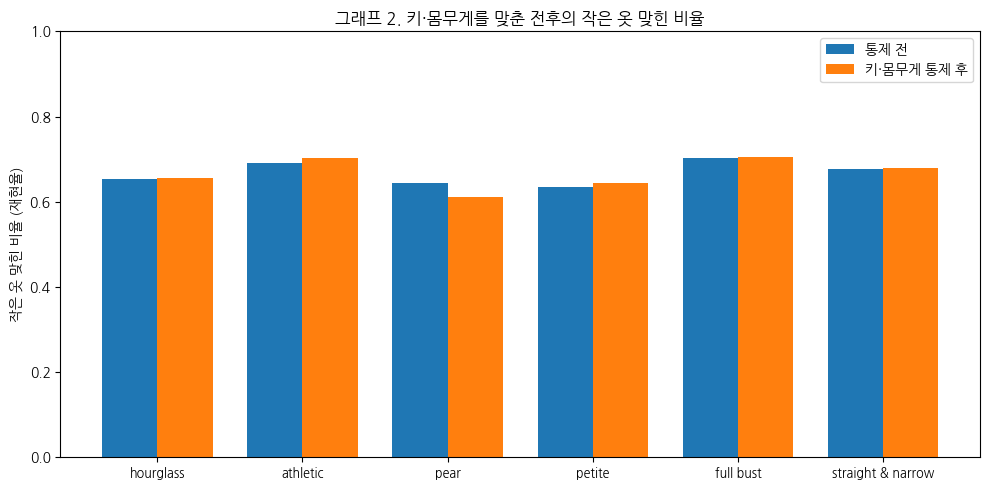

In [ ]:
# ── C. 키·몸무게를 맞춰도 차이가 남는지 ──
# 키 10cm, 몸무게 10kg 단위로 칸을 나누고, 실제로 작았던 옷만 사용
hw = pt.dropna(subset=['height_cm', 'weight_kg']).copy()
hw['칸'] = (pd.cut(hw['height_cm'], [0, 150, 160, 170, 180, 300]).astype(str) + ' / ' +
            pd.cut(hw['weight_kg'], [0, 50, 60, 70, 80, 300]).astype(str))
sm = hw[hw['is_small'] == 1]

# 칸 × 체형별 재현율 (실제 작음 30개 미만 칸은 제외)
cell = sm.groupby(['칸', 'body_type']).agg(실제작음=('is_small', 'sum'), 맞힌작음=('hit_small', 'sum')).reset_index()
cell = cell[cell['실제작음'] >= 30]
cell['재현율'] = cell['맞힌작음'] / cell['실제작음']

# 모든 체형에 똑같은 키·몸무게 구성(전체 비율)을 적용해 점수를 다시 합침
cell['기준비율'] = cell['칸'].map(sm['칸'].value_counts(normalize=True))
adj = {bt: (d['재현율'] * d['기준비율']).sum() / d['기준비율'].sum() for bt, d in cell.groupby('body_type')}

compare = pd.DataFrame({'통제 전': result['작음_재현율'], '키·몸무게 통제 후': pd.Series(adj)}).loc[order]
compare['차이'] = compare['키·몸무게 통제 후'] - compare['통제 전']
display(compare.round(3))

# 그래프 2 (통제 후 점수가 없는 체형은 제외)
o2 = [bt for bt in order if not np.isnan(compare.loc[bt, '키·몸무게 통제 후'])]
fig, ax = plt.subplots(figsize=(10, 5)); x = np.arange(len(o2))
ax.bar(x - w/2, compare.loc[o2, '통제 전'], w, label='통제 전')
ax.bar(x + w/2, compare.loc[o2, '키·몸무게 통제 후'], w, label='키·몸무게 통제 후')
ax.set_xticks(x); ax.set_xticklabels(o2, fontsize=9)
ax.set_ylabel('작은 옷 맞힌 비율 (재현율)'); ax.set_ylim(0, 1); ax.legend()
ax.set_title('그래프 2. 키·몸무게를 맞춘 전후의 작은 옷 맞힌 비율')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프2.png", dpi=300); plt.show()

## 5-2. 새 모델: 키·몸무게를 맞춰도 배형이 낮을까?

**결과**

| 체형 | 그냥 계산 | 키·몸무게 맞춘 뒤 |
| --- | --- | --- |
| pear | 64.4% | **61.2%** (가장 낮음) |
| petite | 63.5% | 64.3% |
| hourglass | 65.4% | 65.5% |
| 나머지 | 거의 그대로 | |

**쉽게 말하면**
- 그냥 계산하면 배형은 다른 체형과 비슷해 보인다.
- 그런데 키·몸무게가 같은 사람끼리 비교하면 **배형이 가장 낮아진다.**
- 배형 고객 중에 AI가 원래 잘 맞히는 몸 크기의 사람이 조금 더 많아서, 점수가 실제보다 좋아 보였던 것이다.

**결론**
같은 몸 크기라면 AI는 배형 고객의 작은 옷을 가장 덜 맞히는 경향이 있다.

> 이 차이가 우연인지는 아직 확인하지 않았다. 확인하려면 오차 범위를 추가로 구해야 한다.

찾은 T: 1.017


,ECE_보정전,ECE_보정후
body_type,,
hourglass,0.157,0.004
athletic,0.140,0.010
pear,0.163,0.011
petite,0.136,0.026
full bust,0.149,0.021
straight & narrow,0.156,0.014
apple,0.162,0.033
전체,0.149,0.003


,AI가 예상한 작음,실제 작음,AI가 예상한 큼,실제 큼
body_type,,,,
hourglass,0.134,0.134,0.127,0.131
athletic,0.139,0.134,0.117,0.120
pear,0.130,0.125,0.138,0.152
petite,0.120,0.128,0.135,0.141
full bust,0.146,0.135,0.132,0.171
straight & narrow,0.129,0.129,0.120,0.115
apple,0.145,0.154,0.134,0.122


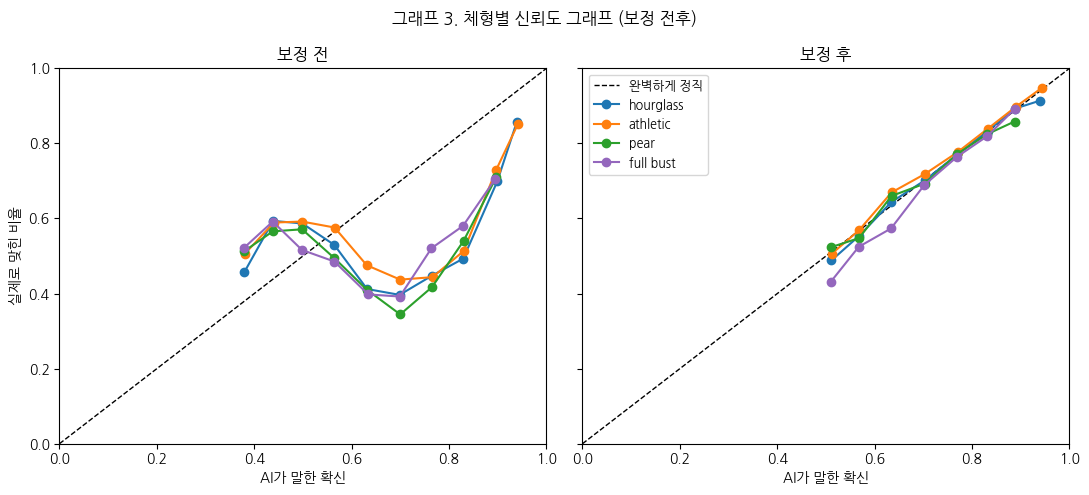

In [ ]:
# ── D. 확신도 보정 (원래 비율 되돌리기 + temperature scaling) ──
def ece(p, y, n_bins=15):
    # AI가 고른 답의 확신과 실제 정답률의 평균 차이 (0에 가까울수록 정직)
    conf, correct = p.max(1), (p.argmax(1) == y)
    bins = np.linspace(0, 1, n_bins + 1); total = 0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum(): total += abs(conf[m].mean() - correct[m].mean()) * m.mean()
    return total

def reliability(p, y, n_bins=15):
    conf, correct = p.max(1), (p.argmax(1) == y)
    bins = np.linspace(0, 1, n_bins + 1); xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 30: xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return xs, ys

# [1단계] 가중치로 부풀린 작음·큼 확률을 실제 비율로 되돌림
log_prior = np.log(train_label.value_counts(normalize=True).sort_index().values)

# [2단계] 보정용 데이터로 temperature T 찾기
zc, yc = pc[zcols].values + log_prior, pc['label'].values
nll = lambda T: -np.log(softmax(zc / T, axis=1)[np.arange(len(yc)), yc] + 1e-12).mean()
T = minimize_scalar(nll, bounds=(0.05, 10), method='bounded').x
print("찾은 T:", round(T, 3))

# 시험용·보정용에 똑같이 적용
pt[qcols] = softmax((pt[zcols].values + log_prior) / T, axis=1)
pc[qcols] = softmax((pc[zcols].values + log_prior) / T, axis=1)

# 체형별 ECE 보정 전후
rows = []
for bt in order + ['전체']:
    d = pt if bt == '전체' else pt[pt['body_type'] == bt]
    rows.append({'body_type': bt, 'ECE_보정전': ece(d[pcols].values, d['label'].values),
                 'ECE_보정후': ece(d[qcols].values, d['label'].values)})
display(pd.DataFrame(rows).set_index('body_type').round(3))

# 작음·큼 확률을 따로 봤을 때: AI가 예상한 비율 vs 실제 비율
exp = pd.DataFrame({
    'AI가 예상한 작음': pt.groupby('body_type')['q_small'].mean(),
    '실제 작음': pt.groupby('body_type')['is_small'].mean(),
    'AI가 예상한 큼': pt.groupby('body_type')['q_large'].mean(),
    '실제 큼': pt.groupby('body_type')['is_large'].mean()}).loc[order]
display(exp.round(3))

# 그래프 3
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, cols, title in [(axes[0], pcols, '보정 전'), (axes[1], qcols, '보정 후')]:
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='완벽하게 정직')
    for bt in ['hourglass', 'athletic', 'pear', 'full bust']:
        d = pt[pt['body_type'] == bt]
        xs, ys = reliability(d[cols].values, d['label'].values)
        ax.plot(xs, ys, marker='o', color=colors[bt], label=bt)
    ax.set_title(title); ax.set_xlabel('AI가 말한 확신'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].set_ylabel('실제로 맞힌 비율'); axes[1].legend(fontsize=9)
fig.suptitle('그래프 3. 체형별 신뢰도 그래프 (보정 전후)')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프3.png", dpi=300); plt.show()

## 5-3. 새 모델: AI의 확신은 체형마다 정직한가?

**보정 전후 ECE** (0에 가까울수록 정직)

| 체형 | 보정 전 | 보정 후 |
| --- | --- | --- |
| hourglass | 0.157 | 0.004 |
| athletic | 0.140 | 0.010 |
| pear | 0.163 | 0.011 |
| petite | 0.136 | 0.026 |
| full bust | 0.149 | 0.021 |
| straight & narrow | 0.156 | 0.014 |
| apple | 0.162 | 0.033 |
| **전체** | 0.149 | **0.003** |

**AI 예상 vs 실제**

| 체형 | 예상한 작음 | 실제 작음 | 예상한 큼 | 실제 큼 |
| --- | --- | --- | --- | --- |
| pear | 13.0% | 12.5% | 13.8% | 15.2% |
| full bust | 14.6% | 13.5% | 13.2% | **17.1%** |
| hourglass | 13.4% | 13.4% | 12.7% | 13.1% |

**결과**
- 보정 후 모든 체형에서 AI는 대체로 정직하다. pear만 특별히 어긋나지 않는다.
- 작은 옷은 모든 체형에서 예상과 실제가 1%p 안팎으로 거의 같다.
- full bust의 큰 옷만 AI 예상(13.2%)보다 실제(17.1%)가 많다. 옷 정보를 넣어도 고쳐지지 않았다.

,작음 AUC,작음 하한,작음 상한,큼 AUC,큼 하한,큼 상한
body_type,,,,,,
hourglass,0.790,0.778,0.803,0.796,0.784,0.809
athletic,0.811,0.797,0.825,0.798,0.781,0.812
pear,0.788,0.767,0.807,0.788,0.769,0.805
petite,0.792,0.768,0.815,0.773,0.755,0.791
full bust,0.788,0.754,0.816,0.838,0.797,0.863
straight & narrow,0.812,0.786,0.835,0.801,0.775,0.825
apple,0.750,0.704,0.797,0.815,0.775,0.851


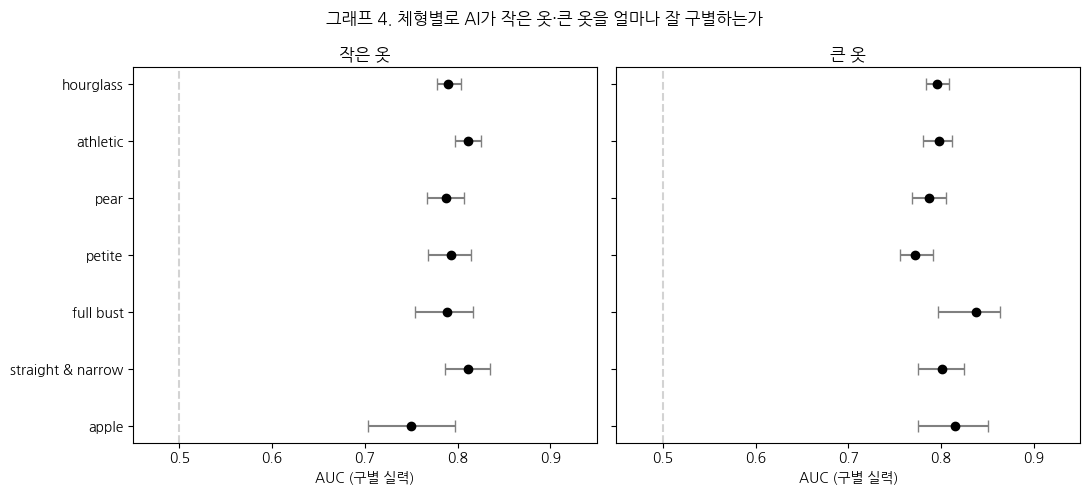

In [ ]:
# ── E. 체형별 구별 실력 (AUC) + 오차 범위 ──
rows = []
for bt in order:
    d = pt[pt['body_type'] == bt].reset_index(drop=True)
    ys, yl = d['is_small'].values, d['is_large'].values
    qs, ql = d['q_small'].values, d['q_large'].values
    idx = d.groupby('user_id').indices; users = np.array(list(idx.keys()))
    bs, bl = [], []
    for _ in range(1000):
        ii = np.concatenate([idx[u] for u in rng.choice(users, len(users))])
        bs.append(roc_auc_score(ys[ii], qs[ii])); bl.append(roc_auc_score(yl[ii], ql[ii]))
    rows.append({'body_type': bt,
                 '작음 AUC': roc_auc_score(ys, qs), '작음 하한': np.percentile(bs, 2.5), '작음 상한': np.percentile(bs, 97.5),
                 '큼 AUC': roc_auc_score(yl, ql), '큼 하한': np.percentile(bl, 2.5), '큼 상한': np.percentile(bl, 97.5)})
auc_df = pd.DataFrame(rows).set_index('body_type')
display(auc_df.round(3))

# 그래프 4
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True); yy = np.arange(len(order))
for ax, c, lo, hi, title in [(axes[0], '작음 AUC', '작음 하한', '작음 상한', '작은 옷'),
                             (axes[1], '큼 AUC', '큼 하한', '큼 상한', '큰 옷')]:
    ax.errorbar(auc_df[c], yy, xerr=[auc_df[c] - auc_df[lo], auc_df[hi] - auc_df[c]],
                fmt='o', color='black', ecolor='gray', capsize=4)
    ax.axvline(0.5, ls='--', color='lightgray')
    ax.set_xlim(0.45, 0.95); ax.set_title(title); ax.set_xlabel('AUC (구별 실력)')
axes[0].set_yticks(yy); axes[0].set_yticklabels(order); axes[0].invert_yaxis()
fig.suptitle('그래프 4. 체형별로 AI가 작은 옷·큰 옷을 얼마나 잘 구별하는가')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프4.png", dpi=300); plt.show()

,공통_작음,공통_맞음,공통_큼,체형결과별_작음,체형결과별_맞음,체형결과별_큼,공통_후보수,체형결과별_후보수
body_type,,,,,,,,
hourglass,0.621,1.0,0.641,0.910,0.905,0.891,1.515,2.090
athletic,0.658,1.0,0.596,0.923,0.896,0.889,1.486,2.009
pear,0.604,1.0,0.658,0.897,0.898,0.880,1.538,2.059
petite,0.589,1.0,0.604,0.881,0.886,0.938,1.511,2.075
full bust,0.686,1.0,0.696,0.904,0.893,0.936,1.576,2.014
straight & narrow,0.663,1.0,0.587,0.929,0.895,0.921,1.451,2.153
apple,0.645,1.0,0.708,0.868,0.903,0.933,1.607,2.185


,후보 1개,후보 2개,후보 3개
row_0,,,
hourglass,0.169,0.572,0.259
athletic,0.205,0.582,0.214
pear,0.182,0.578,0.240
petite,0.185,0.555,0.260
full bust,0.203,0.580,0.217
straight & narrow,0.174,0.500,0.327
apple,0.143,0.529,0.328


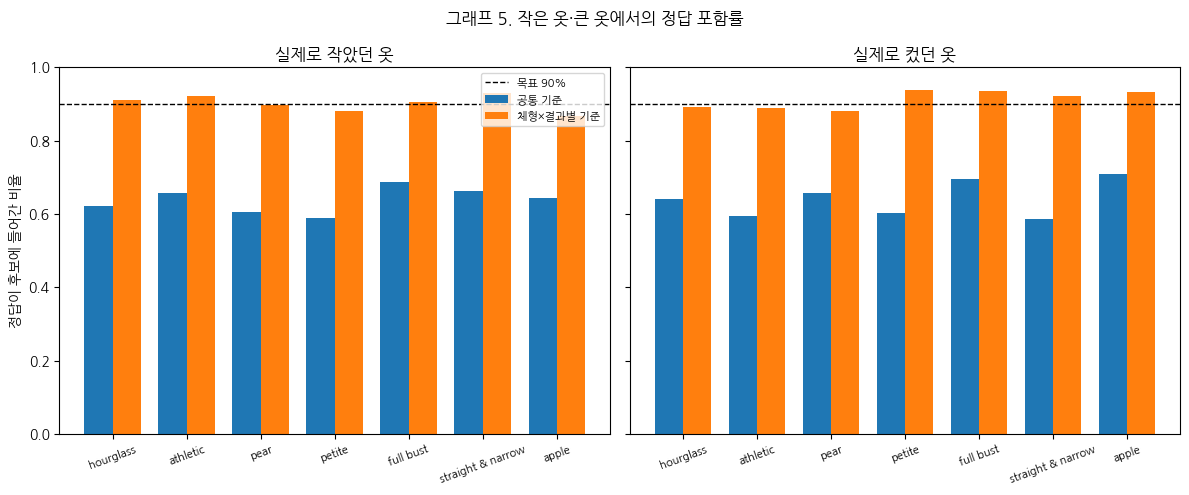

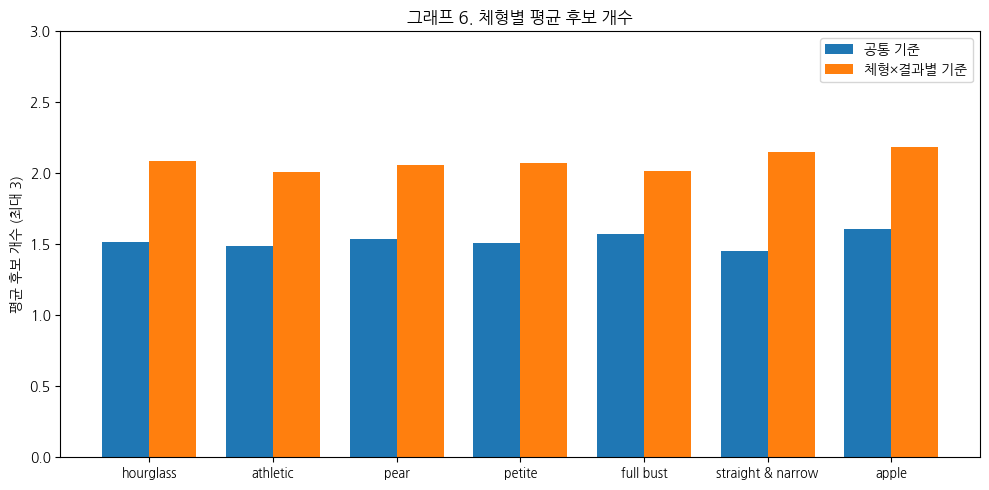

In [ ]:
# ── F. conformal: 공통 기준 vs 체형×결과별 기준 ──
alpha = 0.1   # 목표: 정답이 후보에 90% 들어가게
q_cal, y_cal, bt_cal = pc[qcols].values, pc['label'].values, pc['body_type'].values
q_test, y_test, bt_test = pt[qcols].values, pt['label'].values, pt['body_type'].values

def threshold(scores, alpha):
    # 보정용 점수(1 - 정답에 준 확률)의 90% 지점을 기준값으로
    n = len(scores); level = min(1, np.ceil((n + 1) * (1 - alpha)) / n)
    return np.quantile(scores, level, method='higher')

# [공통 기준] 모든 체형·결과에 기준값 하나
t_all = threshold(1 - q_cal[np.arange(len(y_cal)), y_cal], alpha)
set_all = (1 - q_test) <= t_all

# [체형×결과별 기준] 체형마다, 결과(작음·맞음·큼)마다 기준값을 따로
t_bk = {(bt, k): threshold(1 - q_cal[(bt_cal == bt) & (y_cal == k), k], alpha)
        for bt in order for k in [0, 1, 2]}
t_mat = np.array([[t_bk[(bt, k)] for k in [0, 1, 2]] for bt in bt_test])
set_bk = (1 - q_test) <= t_mat

def coverage_by_label(sets, name):
    # 실제 결과별로 정답이 후보에 들어간 비율
    d = pd.DataFrame({'body_type': bt_test, 'label': y_test,
                      'covered': sets[np.arange(len(y_test)), y_test]})
    t = d.pivot_table(index='body_type', columns='label', values='covered')
    t.columns = [f'{name}_작음', f'{name}_맞음', f'{name}_큼']
    return t

cov = coverage_by_label(set_all, '공통').join(coverage_by_label(set_bk, '체형결과별')).loc[order]
cov['공통_후보수'] = pd.Series(set_all.sum(1)).groupby(bt_test).mean()
cov['체형결과별_후보수'] = pd.Series(set_bk.sum(1)).groupby(bt_test).mean()
display(cov.round(3))

# 후보 1개 / 2개 / 3개 비율 (체형×결과별 기준)
dist = pd.crosstab(bt_test, set_bk.sum(1), normalize='index').loc[order]
dist.columns = [f'후보 {c}개' for c in dist.columns]
display(dist.round(3))

# 그래프 5: 작은 옷·큰 옷 정답 포함률
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True); x = np.arange(len(order))
for ax, kn, title in [(axes[0], '작음', '실제로 작았던 옷'), (axes[1], '큼', '실제로 컸던 옷')]:
    ax.bar(x - w/2, cov[f'공통_{kn}'], w, label='공통 기준')
    ax.bar(x + w/2, cov[f'체형결과별_{kn}'], w, label='체형×결과별 기준')
    ax.axhline(0.9, ls='--', color='black', lw=1, label='목표 90%')
    ax.set_ylim(0, 1); ax.set_title(title)
    ax.set_xticks(x); ax.set_xticklabels(order, fontsize=8, rotation=20)
axes[0].set_ylabel('정답이 후보에 들어간 비율'); axes[0].legend(fontsize=8)
fig.suptitle('그래프 5. 작은 옷·큰 옷에서의 정답 포함률')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프5.png", dpi=300); plt.show()

# 그래프 6: 평균 후보 수
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w/2, cov['공통_후보수'], w, label='공통 기준')
ax.bar(x + w/2, cov['체형결과별_후보수'], w, label='체형×결과별 기준')
ax.set_ylim(0, 3); ax.set_ylabel('평균 후보 개수 (최대 3)')
ax.set_xticks(x); ax.set_xticklabels(order, fontsize=9); ax.legend()
ax.set_title('그래프 6. 체형별 평균 후보 개수')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프6.png", dpi=300); plt.show()

In [ ]:
# ── G. 키·몸무게 통제 후 점수의 오차 범위 ──
# C 셀과 똑같은 방식으로 통제 후 점수를 계산하는 함수
def adjusted_recall(sm_df, ref):
    c = sm_df.groupby(['칸', 'body_type']).agg(
        실제작음=('is_small', 'sum'), 맞힌작음=('hit_small', 'sum')).reset_index()
    c = c[c['실제작음'] >= 30]
    c['재현율'] = c['맞힌작음'] / c['실제작음']
    c['기준비율'] = c['칸'].map(ref)
    return {bt: (d['재현율'] * d['기준비율']).sum() / d['기준비율'].sum()
            for bt, d in c.groupby('body_type')}

# 기준 비율은 원래 데이터로 고정 (매번 바뀌면 비교가 흔들림)
ref = sm['칸'].value_counts(normalize=True)

# 사람 단위로 1000번 다시 뽑아 통제 후 점수를 다시 계산
idx = sm.groupby('user_id').indices
users = np.array(list(idx.keys()))
boot = {bt: [] for bt in order}
for _ in range(1000):
    ii = np.concatenate([idx[u] for u in rng.choice(users, len(users))])
    a = adjusted_recall(sm.iloc[ii], ref)
    for bt in order:
        boot[bt].append(a.get(bt, np.nan))

ci_adj = pd.DataFrame({
    '통제 후': pd.Series(adj),
    '하한': {bt: np.nanpercentile(v, 2.5) for bt, v in boot.items()},
    '상한': {bt: np.nanpercentile(v, 97.5) for bt, v in boot.items()}}).loc[order]
display(ci_adj.round(3))

,통제 후,하한,상한
hourglass,0.655,0.627,0.685
athletic,0.704,0.671,0.734
pear,0.612,0.555,0.656
petite,0.643,0.593,0.703
full bust,0.705,0.635,0.756
straight & narrow,0.680,0.618,0.739
apple,NaN,0.533,0.889


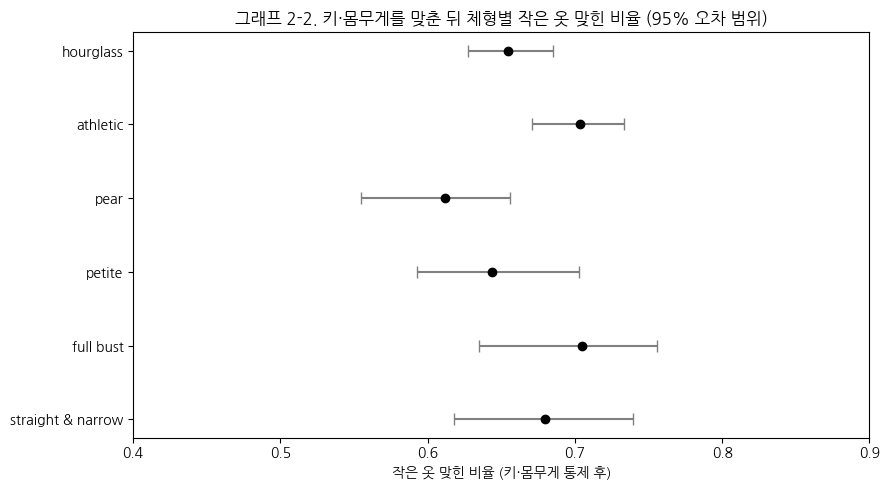

In [ ]:
# 그래프 2-2: 통제 후 점수 + 오차 범위
o2 = [bt for bt in order if not np.isnan(ci_adj.loc[bt, '통제 후'])]
c = ci_adj.loc[o2]
fig, ax = plt.subplots(figsize=(9, 5)); yy = np.arange(len(o2))
ax.errorbar(c['통제 후'], yy, xerr=[c['통제 후'] - c['하한'], c['상한'] - c['통제 후']],
            fmt='o', color='black', ecolor='gray', capsize=4)
ax.set_yticks(yy); ax.set_yticklabels(o2); ax.invert_yaxis()
ax.set_xlim(0.4, 0.9); ax.set_xlabel('작은 옷 맞힌 비율 (키·몸무게 통제 후)')
ax.set_title('그래프 2-2. 키·몸무게를 맞춘 뒤 체형별 작은 옷 맞힌 비율 (95% 오차 범위)')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/그래프2-2.png", dpi=300); plt.show()

## 5-5. 키·몸무게 통제 후 점수의 신뢰성

키·몸무게 통제 후 재현율에 대해 사람 단위 부트스트랩(1,000회)으로 95% 신뢰구간을 산출하였다.

| 체형 | 통제 후 작음 재현율 | 95% 신뢰구간 |
| --- | --- | --- |
| athletic | 0.704 | 0.671 ~ 0.734 |
| full bust | 0.705 | 0.635 ~ 0.756 |
| straight & narrow | 0.680 | 0.618 ~ 0.739 |
| hourglass | 0.655 | 0.627 ~ 0.685 |
| petite | 0.643 | 0.593 ~ 0.703 |
| **pear** | **0.612** | **0.555 ~ 0.656** |

※ apple은 표본 부족으로 통제 후 점수를 산출하지 못하여 제외하였다.

**해석**
- 키·몸무게를 통제하면 pear의 작음 재현율이 가장 낮게 나타난다.
- pear의 신뢰구간은 athletic과 겹치지 않아, **두 체형 간 차이는 통계적으로 유의하다.**
- 그 외 체형과는 신뢰구간이 일부 겹쳐, 유의한 차이로 단정하기 어렵다.

**결론**
옷 정보를 포함한 모델에서도, 동일한 신체 조건에서 pear 고객의 작은 옷을 가장 덜 맞히는 경향이 확인되었다. 다만 모든 체형 대비 유의한 차이는 athletic에 한해 확인되었다.

> 신뢰구간 비교는 보수적인 기준으로, 구간이 일부 겹치더라도 실제 차이가 존재할 가능성은 배제할 수 없다.

# 결론

옷 정보를 포함한 모델(v2)을 주 결과로, 옷 정보가 없는 모델(v1)을 비교 기준으로 삼아 네 가지 연구 질문에 답하였다.

---

### 질문 1. 체형에 따라 사이즈 추천 AI의 성능이 다른가?

**답: 모델에 따라 다르다.**

| 모델 | 작은 옷 재현율 범위 | pear |
| --- | --- | --- |
| v1 (옷 정보 없음) | 55.3% ~ 73.0% | **55.3%로 가장 낮음**, 다른 체형과 유의한 차이 |
| v2 (옷 정보 포함) | 63.5% ~ 70.4% | 64.4%, 다른 체형과 유의한 차이 없음 |

옷 정보가 없는 모델에서는 pear가 뚜렷하게 불리했으나, 옷 정보를 추가하자 체형 간 격차가 크게 줄었다.

---

### 질문 2. 그 차이는 키·몸무게가 아니라 정말 체형 때문인가?

**답: 그렇다. 신체 조건을 통제하면 pear가 가장 불리하다.**

- v1: 통제 후에도 pear가 가장 낮았다 (55.3% → 55.9%).
- v2: 통제 전에는 격차가 가려져 있었으나, 통제 후 pear가 가장 낮아졌다 (64.4% → 61.2%).
- v2에서 pear는 athletic보다 유의하게 낮았다.

---

### 질문 3. AI가 말하는 확신은 체형마다 똑같이 정직한가?

**답: 보정 후에는 대체로 정직하다.**

- 보정 후 전체 ECE: v1 0.108 → 0.008, v2 0.149 → 0.003
- 모든 체형에서 AI가 예상한 작은 옷 비율과 실제 비율이 1%p 안팎으로 일치했다.
- 예외: full bust의 큰 옷은 두 모델 모두 약 4%p 과소 예측하였다.

---

### 질문 4. 체형별로 기준을 다르게 두면 모든 체형이 똑같이 믿을 수 있는 추천을 받는가?

**답: 체형과 결과를 함께 고려한 기준을 두면 그렇다. 다만 대가가 따른다.**

| 기준 | 전체 포함률 | 작은 옷 포함률 (pear) | 평균 후보 수 |
| --- | --- | --- | --- |
| 공통 기준 | 약 90% | 60.4% | 1.5개 |
| 체형×결과별 기준 | 약 90% | **89.7%** | 2.1개 (v1은 2.5개) |

- 공통 기준은 전체 평균으로는 90%를 지키지만, 반품이 생기는 작은 옷·큰 옷에서는 크게 미달했다.
- 체형×결과별 기준을 적용하면 모든 체형이 작은 옷·큰 옷 모두 약 90%를 보장받았다.
- 그 대가로 후보 수가 늘었으며, 모델의 구별 실력이 높을수록(v1 → v2) 그 비용은 줄었다.

---

### 종합

1. 겉으로 공평해 보이는 AI도 신체 조건을 맞춰 비교하면 특정 체형(pear)에 불리할 수 있다.
2. 확률 보정만으로는 이러한 불공평이 해소되지 않는다.
3. 체형과 결과를 함께 고려한 conformal 기준은 모든 체형에 동일한 신뢰 수준을 보장한다.
4. 모델이 더 많은 정보를 학습할수록 체형 간 격차와 공평성 확보 비용이 함께 줄어든다.

In [ ]:
# ── H. 결과 저장 ──
import json

RES_DIR = f"{BASE}/결과표/v2"
os.makedirs(RES_DIR, exist_ok=True)

# [1] D 셀의 ECE 표는 변수로 남겨두지 않았으므로 여기서 다시 계산
ece_rows = []
for bt in order + ['전체']:
    d = pt if bt == '전체' else pt[pt['body_type'] == bt]
    ece_rows.append({'body_type': bt,
                     'ECE_보정전': ece(d[pcols].values, d['label'].values),
                     'ECE_보정후': ece(d[qcols].values, d['label'].values)})
ece_df = pd.DataFrame(ece_rows).set_index('body_type')

# [2] 통제 전후 점수와 통제 후 오차 범위를 한 표로 합침
control_df = compare.join(ci_adj[['하한', '상한']].rename(
    columns={'하한': '통제후_하한', '상한': '통제후_상한'}))

# [3] 결과 표 저장 (엑셀에서 한글이 안 깨지게 utf-8-sig 사용)
tables = {
    '1_체형별_재현율': result,
    '2_키몸무게_통제': control_df,
    '3_ECE_보정전후': ece_df,
    '4_예상vs실제': exp,
    '5_AUC': auc_df,
    '6_conformal_포함률_후보수': cov,
    '7_후보개수_분포': dist,
}
for name, df in tables.items():
    df.round(4).to_csv(f"{RES_DIR}/{name}.csv", encoding='utf-8-sig')

# [4] 모든 표를 엑셀 한 파일에 시트별로 저장 (시트 이름은 31자 제한)
with pd.ExcelWriter(f"{RES_DIR}/전체결과_v2.xlsx") as writer:
    for name, df in tables.items():
        df.round(4).to_excel(writer, sheet_name=name[:31])

# [5] 보정 후 확률과 후보 묶음을 예측결과 폴더에 저장
test_out = pt[['review_id', 'user_id', 'body_type', 'label'] + qcols].copy()
test_out[['공통_작음', '공통_맞음', '공통_큼']] = set_all.astype(int)        # 1이면 후보에 포함
test_out[['체형결과별_작음', '체형결과별_맞음', '체형결과별_큼']] = set_bk.astype(int)
test_out['공통_후보수'] = set_all.sum(1)
test_out['체형결과별_후보수'] = set_bk.sum(1)
test_out.to_csv(f"{PRED_DIR}/시험용_보정확률_v2.csv", index=False)

pc[['review_id', 'user_id', 'body_type', 'label'] + qcols].to_csv(
    f"{PRED_DIR}/보정용_보정확률_v2.csv", index=False)

# [6] 분석에 쓴 설정값 저장 (나중에 똑같이 재현하거나 논문에 적을 때 사용)
settings = {
    '모델': 'LightGBM v2 (옷 정보 포함)',
    '시드': 42,
    'temperature_T': float(T),
    '학습용_정답비율': {'작음': float(np.exp(log_prior[0])),
                       '맞음': float(np.exp(log_prior[1])),
                       '큼': float(np.exp(log_prior[2]))},
    'conformal_alpha': alpha,
    '공통_기준값': float(t_all),
    '체형결과별_기준값': {f"{bt}_{['작음', '맞음', '큼'][k]}": float(v) for (bt, k), v in t_bk.items()},
    '부트스트랩_반복수': 1000,
    '키몸무게_칸': {'키': [150, 160, 170, 180], '몸무게': [50, 60, 70, 80], '최소_실제작음': 30},
}
with open(f"{RES_DIR}/설정값.json", 'w', encoding='utf-8') as f:
    json.dump(settings, f, ensure_ascii=False, indent=2)

# [7] 저장된 파일 확인
print("결과표 폴더:")
for f in sorted(os.listdir(RES_DIR)): print("  ", f)
print("예측결과 폴더:")
for f in sorted(os.listdir(PRED_DIR)): print("  ", f)
print("그래프 폴더:")
for f in sorted(os.listdir(FIG_DIR)): print("  ", f)

결과표 폴더:
   1_체형별_재현율.csv
   2_키몸무게_통제.csv
   3_ECE_보정전후.csv
   4_예상vs실제.csv
   5_AUC.csv
   6_conformal_포함률_후보수.csv
   7_후보개수_분포.csv
   설정값.json
   전체결과_v2.xlsx
예측결과 폴더:
   보정용_보정확률_v2.csv
   보정용_예측확률.csv
   보정용_예측확률_v2.csv
   시험용_보정확률_v2.csv
   시험용_예측확률.csv
   시험용_예측확률_v2.csv
그래프 폴더:
   그래프1.png
   그래프2-2.png
   그래프2.png
   그래프3.png
   그래프4.png
   그래프5.png
   그래프6.png


In [ ]:
# ── 그래프 파일 이름을 한글 설명으로 바꾸기 (그래프/v2 폴더) ──
import os

FIG_DIR = "/content/drive/MyDrive/3-2/시각화 학술제/그래프/v2"

rename_map = {
    '그래프1.png':   '1_체형별_작은옷큰옷_맞힌비율.png',
    '그래프2.png':   '2_키몸무게_통제_전후비교.png',
    '그래프2-2.png': '2-2_키몸무게_통제후_오차범위.png',
    '그래프3.png':   '3_보정전후_신뢰도그래프.png',
    '그래프4.png':   '4_체형별_구별실력_AUC.png',
    '그래프5.png':   '5_후보묶음_정답포함률.png',
    '그래프6.png':   '6_후보묶음_평균후보수.png',
}

for old, new in rename_map.items():
    src, dst = f"{FIG_DIR}/{old}", f"{FIG_DIR}/{new}"
    if os.path.exists(src):
        os.rename(src, dst)
        print(f"{old} → {new}")
    else:
        print(f"{old} 없음 (이미 바뀌었거나 저장 안 됨)")

print("\n현재 그래프/v2 폴더:")
for f in sorted(os.listdir(FIG_DIR)): print("  ", f)

그래프1.png → 1_체형별_작은옷큰옷_맞힌비율.png
그래프2.png → 2_키몸무게_통제_전후비교.png
그래프2-2.png → 2-2_키몸무게_통제후_오차범위.png
그래프3.png → 3_보정전후_신뢰도그래프.png
그래프4.png → 4_체형별_구별실력_AUC.png
그래프5.png → 5_후보묶음_정답포함률.png
그래프6.png → 6_후보묶음_평균후보수.png

현재 그래프/v2 폴더:
   1_체형별_작은옷큰옷_맞힌비율.png
   2-2_키몸무게_통제후_오차범위.png
   2_키몸무게_통제_전후비교.png
   3_보정전후_신뢰도그래프.png
   4_체형별_구별실력_AUC.png
   5_후보묶음_정답포함률.png
   6_후보묶음_평균후보수.png


그래프

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


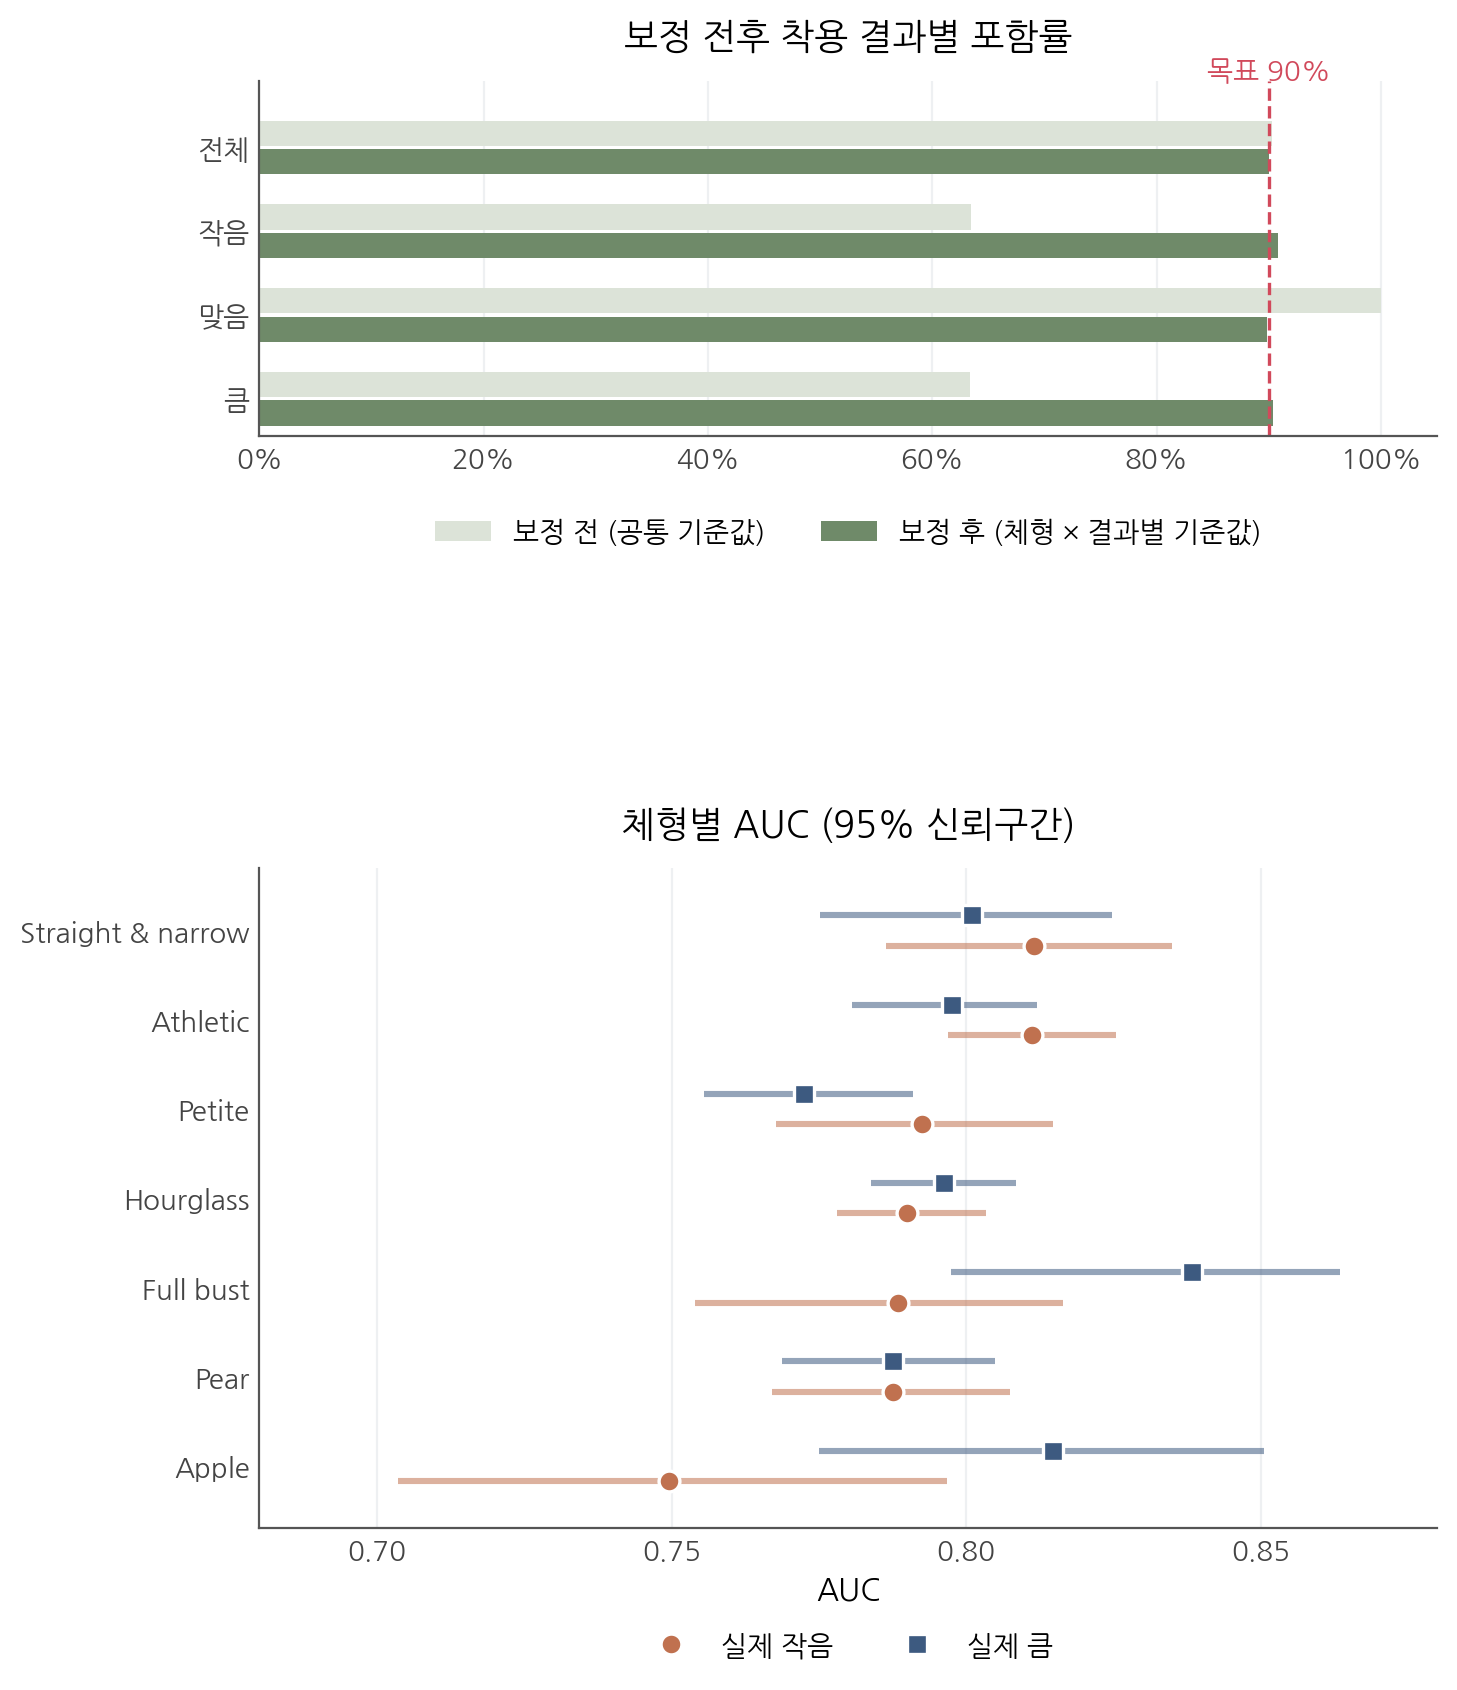

In [ ]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── 경로 ──
BASE     = "/content/drive/MyDrive/3-2/시각화 학술제"
PRED_DIR = f"{BASE}/예측결과"
FIG_DIR  = f"{BASE}/그림"
os.makedirs(FIG_DIR, exist_ok=True)

# ── 데이터 불러오기 ──
cal = pd.read_csv(f"{PRED_DIR}/시험용_보정확률_v2.csv")
auc = pd.read_excel(f"{BASE}/결과표/v2/전체결과_v2.xlsx", sheet_name='5_AUC')

plt.rcParams.update({
    'pdf.fonttype': 42, 'figure.dpi': 200, 'savefig.dpi': 600,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#555555', 'axes.titleweight': 'normal',
})

OUT = {0: '작음', 1: '맞음', 2: '큼'}
NAME_EN = {'hourglass': 'Hourglass', 'athletic': 'Athletic', 'pear': 'Pear',
           'petite': 'Petite', 'full bust': 'Full bust',
           'straight & narrow': 'Straight & narrow', 'apple': 'Apple'}
A_BEFORE, A_AFTER, C_GOAL = '#DCE3D8', '#6F8A69', '#D1495B'
C_SMALL, C_LARGE = '#C0714F', '#3D5A80'

# ── (a)용: 전체 + 착용 결과별 포함률 ──
cond = [cal['label'] == k for k in OUT]
rows = [{'group': '전체',
         'before': np.select(cond, [cal[f'공통_{v}'] for v in OUT.values()]).mean(),
         'after':  np.select(cond, [cal[f'체형결과별_{v}'] for v in OUT.values()]).mean()}]
for k, v in OUT.items():
    d = cal[cal['label'] == k]
    rows.append({'group': v, 'before': d[f'공통_{v}'].mean(),
                 'after': d[f'체형결과별_{v}'].mean()})
res_a = pd.DataFrame(rows)

fig, (axA, axB) = plt.subplots(2, 1, figsize=(7.6, 9.4),
                               gridspec_kw={'height_ratios': [0.62, 1.15], 'hspace': 0.85})
# ── (a) 보정 전후 착용 결과별 포함률 ──
w = 0.3; y = np.arange(len(res_a))
axA.barh(y - w/2 - 0.02, res_a['before'], w, color=A_BEFORE, label='보정 전 (공통 기준값)')
axA.barh(y + w/2 + 0.02, res_a['after'],  w, color=A_AFTER,  label='보정 후 (체형 × 결과별 기준값)')
axA.axvline(0.9, color=C_GOAL, ls='--', lw=1.2)
axA.text(0.9, -0.75, '목표 90%', ha='center', va='bottom', fontsize=10, color=C_GOAL)
axA.set_xlim(0, 1.05)
axA.set_xticks([0, .2, .4, .6, .8, 1]); axA.set_xticklabels(['0%', '20%', '40%', '60%', '80%', '100%'])
axA.set_yticks(y); axA.set_yticklabels(res_a['group'], fontsize=11)
axA.set_ylim(len(res_a) - 0.55, -0.8)
axA.set_title('보정 전후 착용 결과별 포함률', fontsize=13, pad=12)
axA.xaxis.grid(True, color='#EEF0F2'); axA.set_axisbelow(True)
axA.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False, fontsize=10)

# ── (b) 체형별 AUC (95% 신뢰구간) ──
a = auc.set_index('body_type').sort_values('작음 AUC')
yy = np.arange(len(a)); off = 0.17
for key, col, mk, dy, lab in [('작음', C_SMALL, 'o', -off, '실제 작음'),
                              ('큼',   C_LARGE, 's',  off, '실제 큼')]:
    m, lo, hi = a[f'{key} AUC'], a[f'{key} 하한'], a[f'{key} 상한']
    axB.hlines(yy + dy, lo, hi, color=col, lw=2.2, alpha=0.55)
    axB.plot(m, yy + dy, mk, color=col, ms=7.5, mec='white', mew=1.2, label=lab, zorder=3)
axB.set_yticks(yy); axB.set_yticklabels([NAME_EN[b] for b in a.index], fontsize=11)
axB.set_ylim(-0.7, len(a) - 0.3)
axB.set_xlim(0.68, 0.88)
axB.set_xticks([0.70, 0.75, 0.80, 0.85])
axB.set_xlabel('AUC', fontsize=11)
axB.set_title('체형별 AUC (95% 신뢰구간)', fontsize=13, pad=12)
axB.xaxis.grid(True, color='#EEF0F2'); axB.set_axisbelow(True)
axB.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=10)

for ax in (axA, axB):
    ax.tick_params(length=0, labelsize=10, colors='#444444')

fig.savefig(f"{FIG_DIR}/그림_포함률과AUC.pdf", bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_포함률과AUC.png", dpi=600, bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_포함률과AUC.tiff", dpi=600, bbox_inches='tight',
            pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

In [ ]:
import numpy as np
import pandas as pd

PRED_DIR = "/content/drive/MyDrive/3-2/시각화 학술제/예측결과"
TABLE_DIR = "/content/drive/MyDrive/3-2/시각화 학술제/결과표/v2"

raw = pd.read_csv(f"{PRED_DIR}/시험용_예측확률_v2.csv")   # 보정 전 확률 p_*
cal = pd.read_csv(f"{PRED_DIR}/시험용_보정확률_v2.csv")   # 보정 후 확률 q_* + 후보 포함 여부
df = raw[['review_id', 'body_type', 'label', 'p_small', 'p_fit', 'p_large']].merge(
     cal.drop(columns=['user_id', 'body_type', 'label']), on='review_id')

P = ['p_small', 'p_fit', 'p_large']
Q = ['q_small', 'q_fit', 'q_large']
OUT = {0: '작음', 1: '맞음', 2: '큼'}
y = df['label'].values

# ECE: 논문과 같은 15구간
def ece(prob, y, n_bins=15):
    conf, correct = prob.max(1), (prob.argmax(1) == y)
    edges = np.linspace(0, 1, n_bins + 1)
    total = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total

# 집단 간 포함률 격차: 체형 7 × 결과 3 = 21개 집단 포함률의 최대 - 최소
def coverage_gap(hit):
    cells = pd.Series(hit).groupby([df['body_type'], df['label']]).mean()
    return cells.max() - cells.min(), cells

# 각 단계에서 '실제 결과가 후보에 들어갔는지'
hit_raw    = (df[P].values.argmax(1) == y)                                     # 후보 1개 (최고 확률)
hit_common = np.select([y == k for k in OUT], [df[f'공통_{v}'] for v in OUT.values()])
hit_group  = np.select([y == k for k in OUT], [df[f'체형결과별_{v}'] for v in OUT.values()])

rows = []
for name, prob, hit, size in [
        ('보정 전 모델',                    df[P].values, hit_raw,    np.ones(len(df))),
        ('확률 보정 + 공통 기준값',           df[Q].values, hit_common, df['공통_후보수']),
        ('확률 보정 + 체형×결과별 기준값',     df[Q].values, hit_group,  df['체형결과별_후보수'])]:
    gap, cells = coverage_gap(hit)
    rows.append({'방법': name,
                 '전체 정확도': (prob.argmax(1) == y).mean(),
                 'ECE': ece(prob, y),
                 '집단 간 포함률 격차': gap,
                 '평균 추천 후보 수': np.mean(size)})

table = pd.DataFrame(rows).set_index('방법')

# 논문에 넣기 좋은 형태로 표시
table_fmt = pd.DataFrame({
    '전체 정확도':        (table['전체 정확도'] * 100).map('{:.1f}%'.format),
    'ECE':               table['ECE'].map('{:.3f}'.format),
    '집단 간 포함률 격차':  (table['집단 간 포함률 격차'] * 100).map('{:.1f}%p'.format),
    '평균 추천 후보 수':    table['평균 추천 후보 수'].map('{:.2f}개'.format),
}, index=table.index)
display(table_fmt)

table.round(4).to_csv(f"{TABLE_DIR}/표_단계별성능.csv", encoding='utf-8-sig')
table_fmt.to_csv(f"{TABLE_DIR}/표_단계별성능_표기용.csv", encoding='utf-8-sig')

,전체 정확도,ECE,집단 간 포함률 격차,평균 추천 후보 수
방법,,,,
보정 전 모델,52.9%,0.149,41.8%p,1.00개
확률 보정 + 공통 기준값,75.1%,0.003,41.3%p,1.51개
확률 보정 + 체형×결과별 기준값,75.1%,0.003,6.9%p,2.07개


In [ ]:
from scipy.special import softmax

Z = ['z_small', 'z_fit', 'z_large']
y = raw['label'].values

# 1) 온도 T만 적용했을 때: 정확도·ECE가 보정 전과 거의 같아야 함
p_T = softmax(raw[Z].values / 1.017, axis=1)
print('T만 적용  정확도', round((p_T.argmax(1) == y).mean(), 3), ' ECE', round(ece(p_T, y), 3))

# 2) 저장된 보정 확률(q): 0.751 / 0.003
print('저장된 q  정확도', round((df[Q].values.argmax(1) == y).mean(), 3), ' ECE', round(ece(df[Q].values, y), 3))

# 3) 보정 전 모델의 체형별 작음 재현율이 결과표(1_체형별_재현율)와 같은지: hourglass 0.6544
d = raw[raw['label'] == 0]
print((d[P].values.argmax(1) == 0).astype(float).__class__)
print(d.assign(hit=(d[P].values.argmax(1) == 0)).groupby('body_type')['hit'].mean().round(4))

T만 적용  정확도 0.529  ECE 0.148
저장된 q  정확도 0.751  ECE 0.003
<class 'numpy.ndarray'>
body_type
apple                0.7039
athletic             0.6900
full bust            0.7037
hourglass            0.6544
pear                 0.6438
petite               0.6351
straight & narrow    0.6766
Name: hit, dtype: float64


In [ ]:
cal = pd.read_csv(f"{PRED_DIR}/시험용_보정확률_v2.csv")
print('전체 평균', cal[['공통_후보수', '체형결과별_후보수']].mean().round(4).tolist())
print(cal.groupby('body_type')[['공통_후보수', '체형결과별_후보수']].mean().round(4))

전체 평균 [1.514, 2.0653]
                   공통_후보수  체형결과별_후보수
body_type                           
apple              1.6069     2.1854
athletic           1.4863     2.0090
full bust          1.5757     2.0138
hourglass          1.5154     2.0901
pear               1.5379     2.0585
petite             1.5114     2.0749
straight & narrow  1.4511     2.1529


  group  common  group_th
0    전체  0.9022    0.8998
1    작음  0.6342    0.9077
2    맞음  0.9999    0.8977
3     큼  0.6337    0.9035


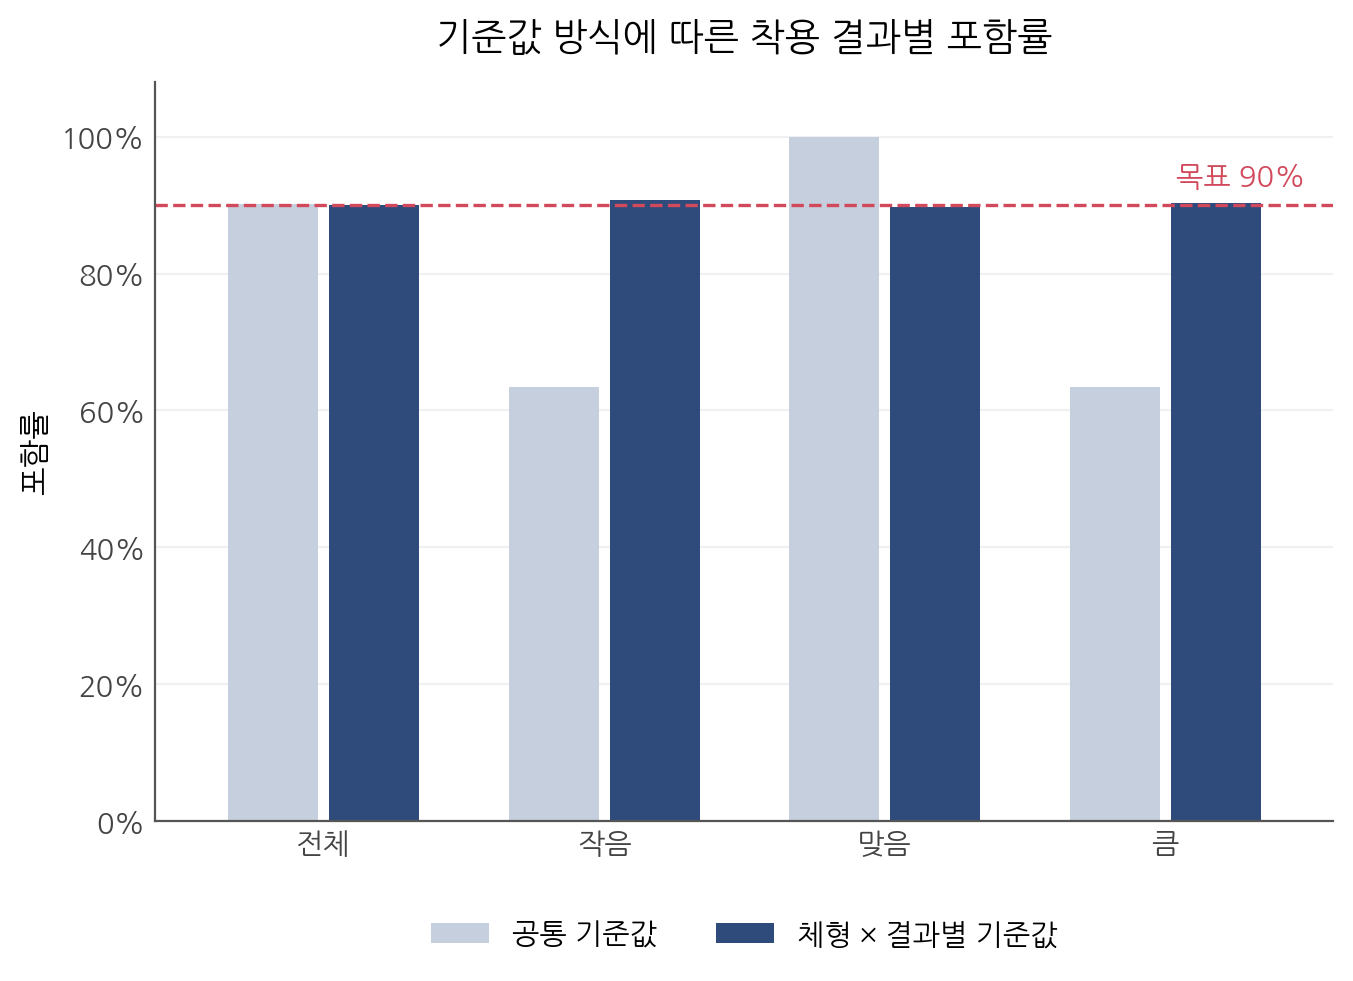

In [ ]:
cal = pd.read_csv(f"{BASE}/예측결과/시험용_보정확률_v2.csv")
FIG_DIR = f"{BASE}/그래프/v2"
OUT = {0: '작음', 1: '맞음', 2: '큼'}

# 전체 + 착용 결과별 포함률
cond = [cal['label'] == k for k in OUT]
rows = [{'group': '전체',
         'common': np.select(cond, [cal[f'공통_{v}'] for v in OUT.values()]).mean(),
         'group_th': np.select(cond, [cal[f'체형결과별_{v}'] for v in OUT.values()]).mean()}]
for k, v in OUT.items():
    d = cal[cal['label'] == k]
    rows.append({'group': v, 'common': d[f'공통_{v}'].mean(),
                 'group_th': d[f'체형결과별_{v}'].mean()})
res = pd.DataFrame(rows)
print(res.round(4))

C_COMMON, C_GROUP, C_GOAL = '#C5CFDD', '#2F4B7C', '#D1495B'

fig, ax = plt.subplots(figsize=(7.6, 4.8))
w = 0.32; x = np.arange(len(res))
ax.bar(x - w/2 - 0.02, res['common'],   w, color=C_COMMON, label='공통 기준값')
ax.bar(x + w/2 + 0.02, res['group_th'], w, color=C_GROUP,  label='체형 × 결과별 기준값')
ax.axhline(0.9, color=C_GOAL, ls='--', lw=1.2)
ax.text(len(res) - 0.5, 0.92, '목표 90%', ha='right', va='bottom', fontsize=10.5, color=C_GOAL)

ax.set_ylim(0, 1.08)
ax.set_yticks([0, .2, .4, .6, .8, 1])
ax.set_yticklabels(['0%', '20%', '40%', '60%', '80%', '100%'])
ax.set_xticks(x); ax.set_xticklabels(res['group'], fontsize=11.5)
ax.set_xlim(-0.6, len(res) - 0.4)
ax.set_ylabel('포함률', fontsize=11)
ax.set_title('기준값 방식에 따른 착용 결과별 포함률', fontsize=13.5, pad=12, fontweight='normal')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, color='#EEF0F2'); ax.set_axisbelow(True)
ax.tick_params(length=0, labelsize=10.5, colors='#444444')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False, fontsize=10.5)

fig.savefig(f"{FIG_DIR}/그림_착용결과별포함률.pdf", bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_착용결과별포함률.png", dpi=600, bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_착용결과별포함률.tiff", dpi=600, bbox_inches='tight',
            pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

In [ ]:
import json
from scipy.special import softmax

raw = pd.read_csv(f"{BASE}/예측결과/시험용_예측확률_v2.csv")
cfg = json.load(open(f"{BASE}/결과표/v2/설정값.json", encoding='utf-8'))
T = cfg['temperature_T']
prior = np.array([cfg['학습용_정답비율'][k] for k in ['작음', '맞음', '큼']])
Z = raw[['z_small', 'z_fit', 'z_large']].values
y = raw['label'].values

def ece(prob, y, n_bins=15):
    conf, correct = prob.max(1), (prob.argmax(1) == y)
    edges = np.linspace(0, 1, n_bins + 1); total = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total

steps = {'보정 전':                       softmax(Z, axis=1),
         '사전확률 복원':                  softmax(Z + np.log(prior), axis=1),
         '사전확률 복원 + 온도 스케일링':    softmax((Z + np.log(prior)) / T, axis=1)}

rows = []
for name, p in steps.items():
    by_bt = [ece(p[raw['body_type'] == b], y[raw['body_type'] == b]) for b in raw['body_type'].unique()]
    rows.append({'단계': name, '전체 ECE': f'{ece(p, y):.3f}',
                 '체형별 ECE': f'{min(by_bt):.3f}~{max(by_bt):.3f}'})

table = pd.DataFrame(rows).set_index('단계')
display(table)
table.to_csv(f"{BASE}/결과표/v2/표_확률보정단계별ECE.csv", encoding='utf-8-sig')

,전체 ECE,체형별 ECE
단계,,
보정 전,0.149,0.136~0.163
사전확률 복원,0.006,0.005~0.030
사전확률 복원 + 온도 스케일링,0.003,0.004~0.033


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ECE 보정 전 0.149 / 보정 후 0.003


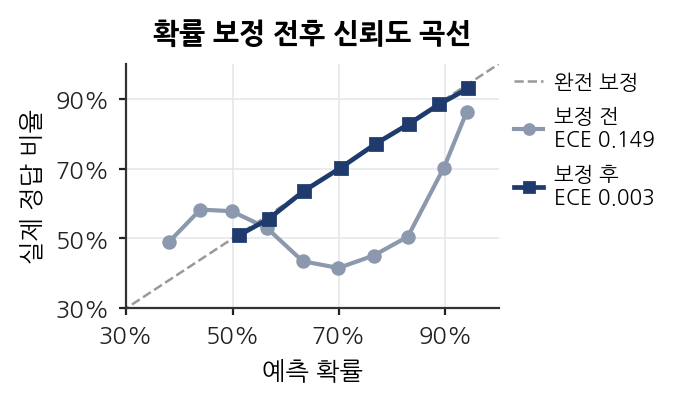

In [10]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE    = "/content/drive/MyDrive/3-2/시각화 학술제"
FIG_DIR = f"{BASE}/그래프/v2"
os.makedirs(FIG_DIR, exist_ok=True)

raw = pd.read_csv(f"{BASE}/예측결과/시험용_예측확률_v2.csv")   # 보정 전 확률 p_*
cal = pd.read_csv(f"{BASE}/예측결과/시험용_보정확률_v2.csv")   # 보정 후 확률 q_*
y_raw, y_cal = raw['label'].values, cal['label'].values

# 15구간 신뢰도 계산 (논문과 같은 방식)
def reliability(prob, y, n_bins=15, min_n=30):
    conf, correct = prob.max(1), (prob.argmax(1) == y)
    edges = np.linspace(0, 1, n_bins + 1)
    xs, ys, ece = [], [], 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() == 0:
            continue
        ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
        if m.sum() >= min_n:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return np.array(xs), np.array(ys), ece

xb, yb, eb = reliability(raw[['p_small', 'p_fit', 'p_large']].values, y_raw)
xa, ya, ea = reliability(cal[['q_small', 'q_fit', 'q_large']].values, y_cal)
print('ECE 보정 전', round(eb, 3), '/ 보정 후', round(ea, 3))   # 0.149 / 0.003 이면 정상

# ── 2단 편집 한 칸 크기: 범례 포함 최종 약 8.5 × 5.2cm ──
FIG_W_CM = 6.1
W = FIG_W_CM / 2.54

plt.rcParams.update({
    'pdf.fonttype': 42, 'figure.dpi': 200, 'savefig.dpi': 650,
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 7.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#333333', 'axes.linewidth': 0.8,
})
C_BEFORE, C_AFTER = '#8C98AD', '#1F3B6E'

fig, ax = plt.subplots(figsize=(W, W * 0.66))
ax.plot([0, 1], [0, 1], ls='--', color='#999999', lw=0.9, label='완전 보정', zorder=1)
ax.plot(xb, yb, marker='o', ms=4.2, lw=1.5, color=C_BEFORE,
        label=f'보정 전\nECE {eb:.3f}', zorder=2)
ax.plot(xa, ya, marker='s', ms=4.0, lw=1.7, color=C_AFTER,
        label=f'보정 후\nECE {ea:.3f}', zorder=3)

ticks = [0.3, 0.5, 0.7, 0.9]
ax.set_xlim(0.3, 1.0); ax.set_ylim(0.3, 1.0)
ax.set_xticks(ticks); ax.set_xticklabels([f'{int(t*100)}%' for t in ticks])
ax.set_yticks(ticks); ax.set_yticklabels([f'{int(t*100)}%' for t in ticks])
ax.set_xlabel('예측 확률')
ax.set_ylabel('실제 정답 비율')
ax.set_title('확률 보정 전후 신뢰도 곡선', pad=8, fontweight='bold')
ax.grid(True, color='#E6E8EB', lw=0.6); ax.set_axisbelow(True)
ax.tick_params(length=2.5, width=0.8, colors='#222222')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False,
          handlelength=1.4, handletextpad=0.5, labelspacing=0.7, borderaxespad=0,
          markerscale=0.85)

fig.savefig(f"{FIG_DIR}/그림_신뢰도곡선.pdf", bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_신뢰도곡선.png", dpi=650, bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_신뢰도곡선.tiff", dpi=650, bbox_inches='tight',
            pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

  group  common  group_th
0    전체  0.9022    0.8998
1    작음  0.6342    0.9077
2    맞음  0.9999    0.8977
3     큼  0.6337    0.9035


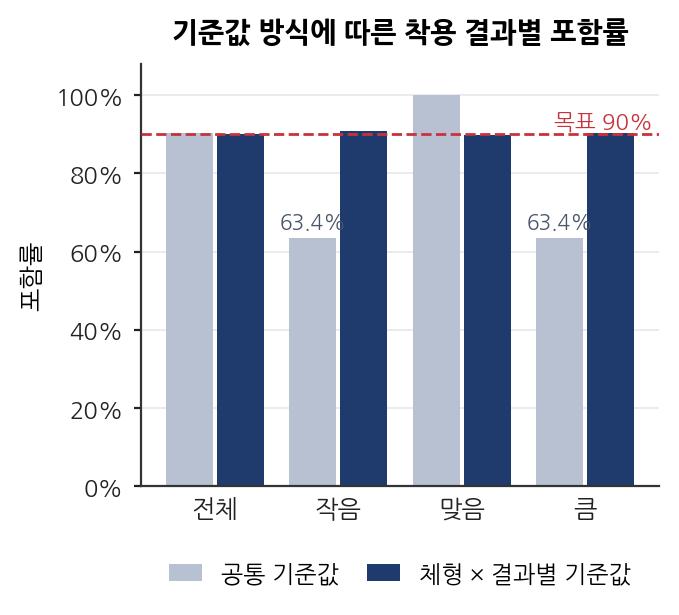

In [11]:
cal = pd.read_csv(f"{BASE}/예측결과/시험용_보정확률_v2.csv")
FIG_DIR = f"{BASE}/그래프/v2"
OUT = {0: '작음', 1: '맞음', 2: '큼'}

# 전체 + 착용 결과별 포함률
cond = [cal['label'] == k for k in OUT]
rows = [{'group': '전체',
         'common': np.select(cond, [cal[f'공통_{v}'] for v in OUT.values()]).mean(),
         'group_th': np.select(cond, [cal[f'체형결과별_{v}'] for v in OUT.values()]).mean()}]
for k, v in OUT.items():
    d = cal[cal['label'] == k]
    rows.append({'group': v, 'common': d[f'공통_{v}'].mean(),
                 'group_th': d[f'체형결과별_{v}'].mean()})
res = pd.DataFrame(rows)
print(res.round(4))

# ── 논문에 들어갈 실제 크기로 그리기 ──
FIG_W_CM = 8.5          # 2단 편집 한 칸 기준
W = FIG_W_CM / 2.54

plt.rcParams.update({
    'pdf.fonttype': 42, 'figure.dpi': 200, 'savefig.dpi': 650,
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 9, 'ytick.labelsize': 8.5, 'legend.fontsize': 8.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#333333', 'axes.linewidth': 0.8, 'axes.titleweight': 'bold',
})
C_COMMON, C_GROUP, C_GOAL = '#B7C1D1', '#1F3B6E', '#C8323C'

fig, ax = plt.subplots(figsize=(W, W * 0.82))
w = 0.38; x = np.arange(len(res))
b1 = ax.bar(x - w/2 - 0.015, res['common'],   w, color=C_COMMON, label='공통 기준값')
b2 = ax.bar(x + w/2 + 0.015, res['group_th'], w, color=C_GROUP,  label='체형 × 결과별 기준값')
ax.axhline(0.9, color=C_GOAL, ls='--', lw=1.0, zorder=3)
ax.text(len(res) - 0.45, 0.905, '목표 90%', ha='right', va='bottom', fontsize=8, color=C_GOAL)

# 목표선과 겹치지 않는 낮은 막대에만 수치 표시
for bars, c in [(b1, '#4A5568'), (b2, C_GROUP)]:
    for b in bars:
        v = b.get_height()
        if v < 0.85:
            ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f'{v*100:.1f}%',
                    ha='center', va='bottom', fontsize=7.5, color=c)

ax.set_ylim(0, 1.08)
ax.set_yticks([0, .2, .4, .6, .8, 1])
ax.set_yticklabels(['0%', '20%', '40%', '60%', '80%', '100%'])
ax.set_xticks(x); ax.set_xticklabels(res['group'])
ax.set_xlim(-0.6, len(res) - 0.4)
ax.set_ylabel('포함률')
ax.set_title('기준값 방식에 따른 착용 결과별 포함률', pad=8, fontweight='bold')
ax.yaxis.grid(True, color='#E6E8EB', lw=0.6); ax.set_axisbelow(True)
ax.tick_params(axis='x', length=0, pad=4, colors='#222222')
ax.tick_params(axis='y', length=2.5, width=0.8, colors='#222222')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False,
          handlelength=1.4, columnspacing=1.2)

fig.savefig(f"{FIG_DIR}/그림_착용결과별포함률.pdf", bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_착용결과별포함률.png", dpi=650, bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_착용결과별포함률.tiff", dpi=650, bbox_inches='tight',
            pil_kwargs={'compression': 'tiff_lzw'})
plt.show()